# TPI IA Primavera 2026: Comprensión visual de escenas (Grupo 24)

**Objetivo:** convertir una foto en una descripción estructurada de la escena (un *SceneJSON*) y contestar preguntas sobre la foto leyendo solo ese JSON.

**Cómo funciona, en una línea:**

> Foto → **YOLO-World + OWLv2** encuentran los objetos (cajas) → **SAM2** recorta su forma exacta (máscaras) → calculamos posición, tamaño, color y relaciones → **SceneJSON** → un motor con reglas contesta las preguntas → **Qwen** (un LLM chico) interpreta preguntas en lenguaje natural y redacta las respuestas.

**Recorrido de la notebook**

| Sección | Qué hace |
|---|---|
| 1. Datos y EDA | Carga los datos y analiza cómo es el dataset |
| 2. Configuración | Junta todos los parámetros en un solo lugar (`CONFIG`) |
| 3. Trazabilidad | Registra qué pasó en cada etapa de cada imagen |
| 4. Detección | Encuentra objetos combinando YOLO-World y OWLv2 |
| 5. Segmentación | Obtiene la máscara de cada objeto con SAM2 |
| 6. SceneJSON | Calcula propiedades y arma el JSON de la escena |
| 7. Pipeline | Encadena las etapas anteriores |
| 8. Evaluación | Mide el F1 contra las anotaciones y compara configuraciones |
| 9. Preguntas (determinista) | Contesta preguntas con código, sin LLM |
| 10. Preguntas (LLM) | Usa Qwen para interpretar preguntas y redactar respuestas y descripciones |
| 11. Test y submission | Procesa las 60 imágenes de test y genera `submission.csv` |
| 12. Análisis de errores | Estudia dónde y por qué falla la pipeline |
| 13. Resumen | F1 final de cajas y máscaras |

**Para correrla en Kaggle:** activar *Accelerator → GPU* e *Internet*, y agregar la competencia con *Add Input → Competition Datasets*. Después, *Save Version → Save & Run All* para que queden guardadas todas las salidas.

# 1. Datos y análisis exploratorio (EDA)

## Carga de los datos
Usamos dos fuentes:

- **Dataset de desarrollo** (`ds-comprension-visual-de-escenas`): 120 imágenes con sus anotaciones en formato LVIS. Lo descarga `kagglehub` y queda accesible como `dataset_tpi`. Sirve para explorar los datos y para medir qué tan bien funciona la pipeline.
- **Archivos de la competencia**: las 60 imágenes de test (sin anotaciones), el formato que debe tener el JSON (`scene_schema.json`), el ejemplo de entrega (`sample_submission.csv`) y las preguntas de desarrollo (`questions_dev.jsonl`). Se agregan a la notebook con *Add Input → Competition Datasets*.

In [1]:
import os, glob

# Dataset de desarrollo: 120 imágenes con anotaciones (lo baja kagglehub)
import kagglehub
dir_dataset = kagglehub.dataset_download("martingra/ds-comprension-visual-de-escenas")
if not os.path.exists("dataset_tpi"):
    os.symlink(dir_dataset, "dataset_tpi")   # acceso corto: dataset_tpi/annotations.json, dataset_tpi/images/

# Archivos de la competencia: imágenes de test, scene_schema.json, sample_submission.csv y preguntas.
# Se agregan a la notebook con Add Input > Competition Datasets y quedan dentro de /kaggle/input.
competencia = glob.glob("/kaggle/input/**/sample_submission.csv", recursive=True)
assert competencia, "Falta agregar la competencia: Add Input > Competition Datasets"
DIR_COMPETENCIA = os.path.dirname(competencia[0])

print("Contenido del dataset:", os.listdir("dataset_tpi"))
print("Archivos de la competencia en:", DIR_COMPETENCIA, os.listdir(DIR_COMPETENCIA))

Contenido del dataset: ['LICENSES.md', 'README.md', 'annotations.json', 'attribution.csv', 'dataset-cover-image.png', 'dataset-metadata.json', 'images']
Archivos de la competencia en: /kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas ['tpi_ia_2026_competition_public', 'sample_submission.csv', 'README_COMPETITION_DATA.md', 'development', 'tpi_2026_qa_public', 'scene_schema.json']


## Primer vistazo a las anotaciones
Leemos `annotations.json` y contamos imágenes, categorías y objetos anotados. También mostramos la ficha de una imagen, porque trae dos listas que son clave para evaluar:

- `neg_category_ids`: categorías que **se verificó que no están** en la imagen. Si el modelo detecta una de estas, es un error seguro.
- `not_exhaustive_category_ids`: categorías que están, pero **no se anotaron todas sus instancias**. Una detección extra de estas no se puede contar como error.

In [2]:
import json

# Cargar el archivo JSON de anotaciones
ruta_anotaciones = 'dataset_tpi/annotations.json'

with open(ruta_anotaciones, 'r') as f:
    datos_lvis = json.load(f)

# Ver la estructura principal
print("Estructura principal:", datos_lvis.keys())
print(f"Total de imágenes: {len(datos_lvis['images'])}")
print(f"Total de categorías: {len(datos_lvis['categories'])}")
print(f"Total de anotaciones (instancias): {len(datos_lvis['annotations'])}")

# Explorar la primera imagen para ver las listas de exhaustividad (neg_category_ids, etc.)
print("\nEjemplo de la primera imagen en el dataset:")
print(json.dumps(datos_lvis['images'][0], indent=2))

Estructura principal: dict_keys(['info', 'licenses', 'images', 'categories', 'annotations'])
Total de imágenes: 120
Total de categorías: 120
Total de anotaciones (instancias): 1790

Ejemplo de la primera imagen en el dataset:
{
  "id": 1,
  "file_name": "tpi_0001.jpg",
  "width": 480,
  "height": 640,
  "license": 3,
  "neg_category_ids": [
    1,
    7
  ],
  "not_exhaustive_category_ids": []
}


## Librería LVIS
Las anotaciones siguen el formato de **LVIS**, un dataset grande de detección. La librería `lvis` permite consultarlas fácilmente (por ejemplo, "todas las anotaciones de esta imagen") y la usamos también para leer las máscaras reales al evaluar.

In [3]:
# Instalar la API de LVIS para Python
!pip install lvis

# Probar la importación
from lvis import LVIS
lvis_gt = LVIS(ruta_anotaciones)
print("\nLVIS inicializado correctamente con", len(lvis_gt.imgs), "imágenes.")


LVIS inicializado correctamente con 120 imágenes.


## Categorías más frecuentes
Hay 1790 objetos anotados repartidos en 120 categorías. Vemos cuáles aparecen más: esas clases van a pesar más en el F1, así que conviene que el detector las encuentre bien.

In [4]:
import pandas as pd

# Extraer categorías
categorias = lvis_gt.cats
df_cats = pd.DataFrame.from_dict(categorias, orient='index')

# Extraer las anotaciones (bounding boxes)
anotaciones = lvis_gt.anns
df_anns = pd.DataFrame.from_dict(anotaciones, orient='index')

# Cruzar para ver cuáles son las categorías con más instancias (cajas)
conteo_instancias = df_anns['category_id'].value_counts().reset_index()
conteo_instancias.columns = ['category_id', 'cantidad_cajas']
df_analisis = conteo_instancias.merge(df_cats, left_on='category_id', right_on='id')

# Mostrar el Top 10 de clases más frecuentes
print(df_analisis[['name', 'cantidad_cajas']].head(10))

      name  cantidad_cajas
0     book              46
1      car              44
2    chair              40
3      box              40
4    wheel              37
5   pillow              31
6     shoe              31
7  curtain              29
8   person              29
9     sock              28


## Ejemplo de imagen con sus anotaciones
Dibujamos las cajas reales (el *ground truth*) sobre la primera imagen. Sirve para ver qué tipo de escenas hay y para comprobar que estamos leyendo bien las coordenadas, que en LVIS vienen como `[x, y, ancho, alto]`.

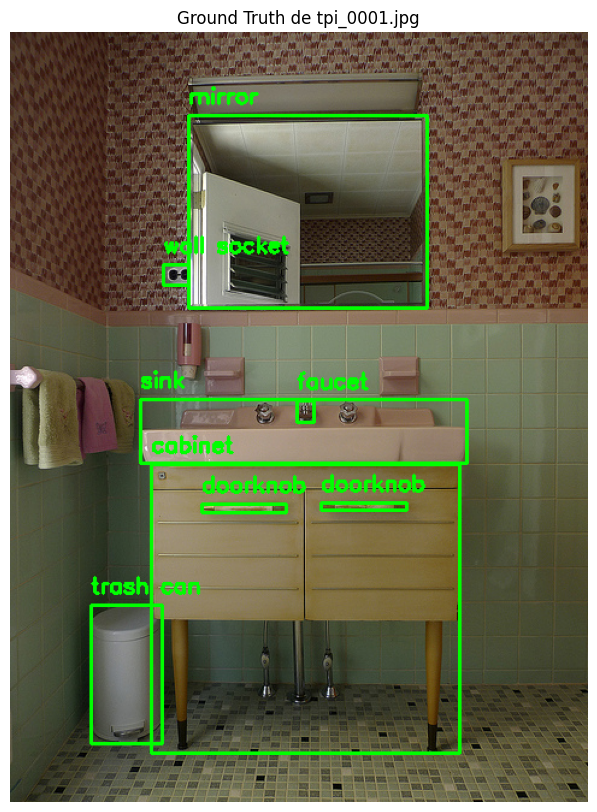

In [5]:
import matplotlib.pyplot as plt
import cv2
import os

# Tomar el ID de la primera imagen cargada en la API
img_id = lvis_gt.get_img_ids()[0]
info_img = lvis_gt.load_imgs([img_id])[0]
ruta_img = os.path.join('dataset_tpi/images', info_img['file_name'])

# Cargar imagen con OpenCV (pasando de BGR a RGB para Matplotlib)
imagen = cv2.imread(ruta_img)
imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# Obtener anotaciones reales para esta imagen
ann_ids = lvis_gt.get_ann_ids(img_ids=[img_id])
anns = lvis_gt.load_anns(ann_ids)

# Dibujar las cajas
for ann in anns:
    bbox = ann['bbox'] # Formato LVIS: [x_min, y_min, ancho, alto]
    x, y, w, h = [int(v) for v in bbox]
    cv2.rectangle(imagen, (x, y), (x+w, y+h), (0, 255, 0), 2)

    # Agregar etiqueta de categoría
    nombre_cat = lvis_gt.cats[ann['category_id']]['name']
    cv2.putText(imagen, nombre_cat, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

plt.figure(figsize=(10, 10))
plt.imshow(imagen)
plt.axis('off')
plt.title(f"Ground Truth de {info_img['file_name']}")
plt.show()

## ¿Cuántos objetos hay por imagen?
Si las escenas tienen muchos objetos, el detector tiene que poder devolver muchas cajas por imagen. Este número justifica el límite `max_objetos` y anticipa qué tan difíciles van a ser las preguntas de conteo.

count    120.000000
mean      14.916667
std       11.567546
min        5.000000
25%        8.000000
50%       10.500000
75%       15.250000
max       66.000000
dtype: float64


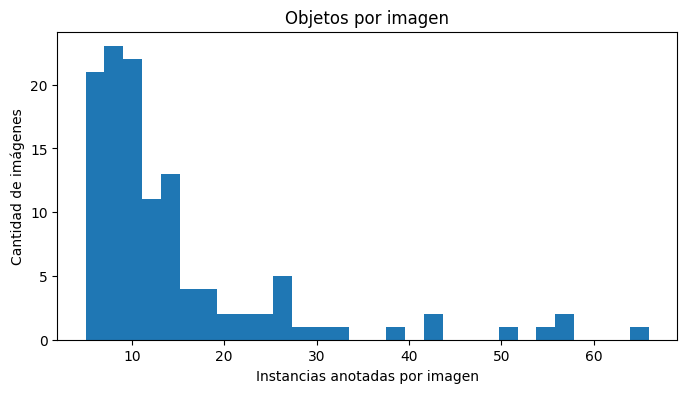

In [6]:
import numpy as np

objetos_por_imagen = df_anns.groupby('image_id').size()
print(objetos_por_imagen.describe())

plt.figure(figsize=(8, 4))
plt.hist(objetos_por_imagen, bins=30)
plt.xlabel("Instancias anotadas por imagen")
plt.ylabel("Cantidad de imágenes")
plt.title("Objetos por imagen")
plt.show()

## ¿Qué tan grandes son los objetos?
Medimos el área de cada objeto como porcentaje de la imagen. Los objetos chicos son los más difíciles de detectar y de recortar. Esta distribución justifica la resolución con la que trabaja el detector y los cortes que usamos para decir si un objeto es *small*, *medium* o *large*.

count    1790.000000
mean        0.018992
std         0.051751
min         0.000004
25%         0.000798
50%         0.002889
75%         0.012700
90%         0.046831
max         0.958880
Name: area_relativa, dtype: float64

Objetos con menos del 1% de la imagen: 71.1 %


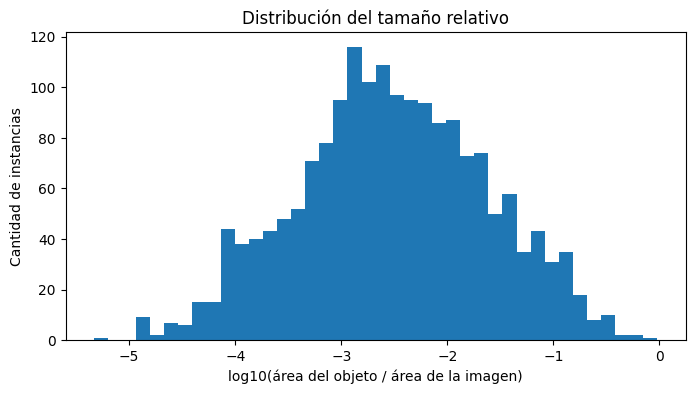

In [7]:
tam_imagen = {img['id']: img['width'] * img['height'] for img in datos_lvis['images']}
df_anns['area_relativa'] = df_anns['area'] / df_anns['image_id'].map(tam_imagen)

print(df_anns['area_relativa'].describe(percentiles=[0.25, 0.5, 0.75, 0.9]))
print("\nObjetos con menos del 1% de la imagen:", round((df_anns['area_relativa'] < 0.01).mean() * 100, 1), "%")

plt.figure(figsize=(8, 4))
plt.hist(np.log10(df_anns['area_relativa'] + 1e-6), bins=40)
plt.xlabel("log10(área del objeto / área de la imagen)")
plt.ylabel("Cantidad de instancias")
plt.title("Distribución del tamaño relativo")
plt.show()

## ¿Cuántas categorías se pueden evaluar en cada imagen?
LVIS usa **anotación federada**: en cada imagen no se revisaron las 120 categorías, solo algunas. Para cada imagen contamos:

- **positivas:** categorías anotadas (están en la imagen);
- **negativas:** se verificó que no están;
- **no verificadas:** nadie revisó si están o no.

Una detección de una categoría no verificada no se puede contar ni como acierto ni como error, así que se ignora. Por eso, además de la precisión, informamos la **cobertura**: qué parte de nuestras detecciones se pudo evaluar.

In [8]:
df_imgs = pd.DataFrame(datos_lvis['images'])
df_imgs['n_negativas'] = df_imgs['neg_category_ids'].apply(len)
df_imgs['n_no_exhaustivas'] = df_imgs['not_exhaustive_category_ids'].apply(len)
df_imgs['n_positivas'] = df_imgs['id'].map(df_anns.groupby('image_id')['category_id'].nunique()).fillna(0)
df_imgs['n_no_verificadas'] = len(datos_lvis['categories']) - df_imgs['n_positivas'] - df_imgs['n_negativas']

print(df_imgs[['n_positivas', 'n_negativas', 'n_no_exhaustivas', 'n_no_verificadas']].describe().round(1))
print("\nTamaños de imagen más comunes:")
print(df_imgs.groupby(['width', 'height']).size().sort_values(ascending=False).head())

       n_positivas  n_negativas  n_no_exhaustivas  n_no_verificadas
count        120.0        120.0             120.0             120.0
mean           6.4          1.0               0.4             112.6
std            1.4          1.0               0.7               1.9
min            3.0          0.0               0.0             108.0
25%            6.0          0.0               0.0             112.0
50%            7.0          1.0               0.0             112.0
75%            7.2          2.0               1.0             114.0
max            8.0          4.0               4.0             117.0

Tamaños de imagen más comunes:
width  height
640    480       26
       427       11
480    640       10
427    640        8
500    375        6
dtype: int64


## ¿Hay categorías con pocos ejemplos?
Si una clase aparece solo 2 o 3 veces, un solo acierto o error cambia mucho su F1. Estas clases conviene mirarlas aparte en el análisis de errores en lugar de sacar conclusiones de ellas.

In [9]:
instancias_por_cat = df_anns['category_id'].value_counts()
print("Categorías con alguna instancia:", len(instancias_por_cat))
print("Categorías con 3 instancias o menos:", (instancias_por_cat <= 3).sum())
print("Categorías sin ninguna instancia anotada:", len(datos_lvis['categories']) - len(instancias_por_cat))

Categorías con alguna instancia: 120
Categorías con 3 instancias o menos: 2
Categorías sin ninguna instancia anotada: 0


## ¿Cuánto se superponen los objetos anotados?
Medimos el IoU de caja entre **todos los pares de objetos anotados de una misma imagen**, separando los pares de la misma clase y los de clases distintas. Responde dos preguntas de diseño:

- **NMS:** si muchos pares reales de la misma clase superan cierto IoU, un NMS con ese umbral borraría objetos verdaderos.
- **Filtro de contención:** si es raro que un objeto real de una clase quede casi entero dentro de otro de la misma clase, borrar esas cajas como duplicados es seguro.

También medimos cuántos pares tienen máscaras que se tocan, que es lo que define la relación `overlaps` del SceneJSON. Solo se usan las anotaciones, como el resto del EDA.

Pares de objetos anotados analizados: 20417
Columnas iou_mayor_nms y contenida_mayor_contencion: con nms_iou = 0.6 y contencion_iomin = 0.75


,pares,cajas_se_tocan,iou_mayor_0_3,iou_mayor_0_5,iou_mayor_nms,contenida_mayor_contencion,mascaras_se_tocan
misma_clase,,,,,,,
clases distintas,16581,0.0879,0.0058,0.0025,0.0020,0.0387,0.0449
misma clase,3836,0.1160,0.0107,0.0050,0.0026,0.0177,0.0532



Pares reales de la misma clase que suprimiría un NMS con cada umbral de IoU:
  NMS con IoU 0.3: suprimiría el 1.07 % de los pares reales (41 pares)
  NMS con IoU 0.4: suprimiría el 0.68 % de los pares reales (26 pares)
  NMS con IoU 0.5: suprimiría el 0.50 % de los pares reales (19 pares)
  NMS con IoU 0.6: suprimiría el 0.26 % de los pares reales (10 pares)
  NMS con IoU 0.7: suprimiría el 0.13 % de los pares reales (5 pares)


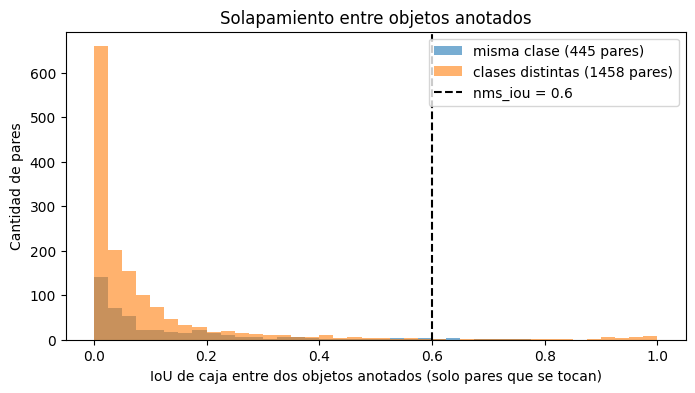

In [10]:
def iou_y_contencion(a, b):
    """Cajas LVIS [x, y, ancho, alto] -> (IoU, intersección / área de la caja más chica)."""
    ax2, ay2, bx2, by2 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    inter = max(0, min(ax2, bx2) - max(a[0], b[0])) * max(0, min(ay2, by2) - max(a[1], b[1]))
    area_a, area_b = a[2] * a[3], b[2] * b[3]
    union = area_a + area_b - inter
    return (inter / union if union > 0 else 0.0), (inter / min(area_a, area_b) if min(area_a, area_b) > 0 else 0.0)

filas = []
for img_id in lvis_gt.get_img_ids():
    anns_img = lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[img_id]))
    mascaras_img = {}
    for i in range(len(anns_img)):
        for j in range(i + 1, len(anns_img)):
            a, b = anns_img[i], anns_img[j]
            iou, contencion = iou_y_contencion(a["bbox"], b["bbox"])
            mascaras_se_tocan = False
            if contencion > 0:   # solo miramos las máscaras si las cajas se tocan
                for ann in (a, b):
                    if ann["id"] not in mascaras_img:
                        mascaras_img[ann["id"]] = lvis_gt.ann_to_mask(ann).astype(bool)
                mascaras_se_tocan = bool(np.logical_and(mascaras_img[a["id"]], mascaras_img[b["id"]]).any())
            filas.append({"image_id": img_id, "misma_clase": a["category_id"] == b["category_id"],
                          "iou": iou, "contencion": contencion, "mascaras_se_tocan": mascaras_se_tocan})
df_pares = pd.DataFrame(filas)
NMS_IOU, CONTENCION = 0.6, 0.75   # valores que después usa CONFIG (sección 2): nms_iou y contencion_iomin

resumen = df_pares.groupby("misma_clase").agg(
    pares=("iou", "size"),
    cajas_se_tocan=("iou", lambda s: (s > 0).mean()),
    iou_mayor_0_3=("iou", lambda s: (s > 0.3).mean()),
    iou_mayor_0_5=("iou", lambda s: (s > 0.5).mean()),
    iou_mayor_nms=("iou", lambda s: (s > NMS_IOU).mean()),
    contenida_mayor_contencion=("contencion", lambda s: (s >= CONTENCION).mean()),
    mascaras_se_tocan=("mascaras_se_tocan", "mean"),
).rename(index={True: "misma clase", False: "clases distintas"})
print("Pares de objetos anotados analizados:", len(df_pares))
print(f"Columnas iou_mayor_nms y contenida_mayor_contencion: con nms_iou = {NMS_IOU} y contencion_iomin = {CONTENCION}")
display(resumen.round(4))

misma = df_pares[df_pares.misma_clase]
print("\nPares reales de la misma clase que suprimiría un NMS con cada umbral de IoU:")
for umbral in (0.3, 0.4, 0.5, 0.6, 0.7):
    print(f"  NMS con IoU {umbral}: suprimiría el {(misma.iou > umbral).mean() * 100:.2f} % de los pares reales "
          f"({int((misma.iou > umbral).sum())} pares)")

df_pares.to_csv("eda_solapamiento_pares.csv", index=False)
plt.figure(figsize=(8, 4))
for valor, etiqueta in ((True, "misma clase"), (False, "clases distintas")):
    ious = df_pares[(df_pares.misma_clase == valor) & (df_pares.iou > 0)].iou
    plt.hist(ious, bins=40, range=(0, 1), alpha=0.6, label=f"{etiqueta} ({len(ious)} pares)")
plt.axvline(NMS_IOU, color="black", linestyle="--", label=f"nms_iou = {NMS_IOU}")
plt.xlabel("IoU de caja entre dos objetos anotados (solo pares que se tocan)")
plt.ylabel("Cantidad de pares")
plt.title("Solapamiento entre objetos anotados")
plt.legend()
plt.show()

## ¿Dónde están los objetos en la imagen?
Asignamos cada objeto anotado a una de las 9 regiones oficiales de la grilla 3×3 usando el **centroide de su máscara**, con la misma regla que usa la pipeline para el campo `position`. Si los objetos se concentraran en pocas celdas, una respuesta por defecto podría acertar seguido; si están repartidos, la posición tiene que calcularse objeto por objeto.

Objetos anotados por región (centroide de la máscara):


,izquierda,centro,derecha,total
arriba,137,145,162,444
medio,203,346,237,786
abajo,158,236,166,560
total,498,727,565,1790


Porcentaje del total por región:


,izquierda,centro,derecha
arriba,7.7,8.1,9.1
medio,11.3,19.3,13.2
abajo,8.8,13.2,9.3


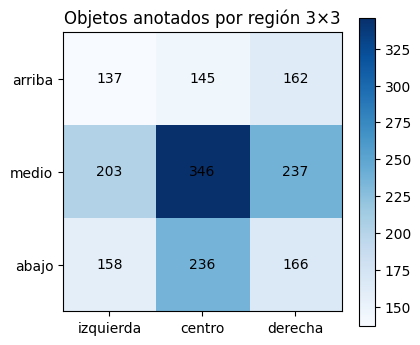

In [11]:
filas_ = ["arriba", "medio", "abajo"]
columnas_ = ["izquierda", "centro", "derecha"]
conteo_grilla = np.zeros((3, 3), dtype=int)
for ann in lvis_gt.load_anns(lvis_gt.get_ann_ids()):
    mascara = lvis_gt.ann_to_mask(ann).astype(bool)
    if not mascara.any():
        continue
    h, w = mascara.shape
    ys, xs = np.nonzero(mascara)
    cx, cy = xs.mean() / w, ys.mean() / h
    conteo_grilla[min(int(cy * 3), 2), min(int(cx * 3), 2)] += 1

df_grilla = pd.DataFrame(conteo_grilla, index=filas_, columns=columnas_)
df_grilla["total"] = df_grilla.sum(axis=1)
df_grilla.loc["total"] = df_grilla.sum(axis=0)
print("Objetos anotados por región (centroide de la máscara):")
display(df_grilla)
print("Porcentaje del total por región:")
display((pd.DataFrame(conteo_grilla, index=filas_, columns=columnas_) / conteo_grilla.sum() * 100).round(1))
df_grilla.to_csv("eda_grilla_3x3.csv")

plt.figure(figsize=(4.5, 4))
plt.imshow(conteo_grilla, cmap="Blues")
for f in range(3):
    for c in range(3):
        plt.text(c, f, conteo_grilla[f, c], ha="center", va="center")
plt.xticks(range(3), columnas_)
plt.yticks(range(3), filas_)
plt.title("Objetos anotados por región 3×3")
plt.colorbar()
plt.show()

> **Conclusiones del EDA:**
> - **Objetos por imagen:** media 14,9, mediana 10,5 y máximo 66 (cola larga a derecha). Por eso el tope `max_objetos` es 100: un tope cercano a la media recortaría objetos reales en las escenas densas.
> - **Tamaño de los objetos:** el 71,1 % ocupa menos del 1 % de la imagen y la mediana es 0,29 %. Por eso no reducimos la resolución de los detectores, sumamos un segundo detector y usamos cortes de tamaño de 1 % y 10 % (`cortes_tamano`).
> - **Categorías evaluables:** en promedio solo 6,4 positivas y 1,0 negativa por imagen; 112,6 de las 120 categorías no están verificadas. Por eso informamos la cobertura junto con la precisión.
> - **Clases con 3 instancias o menos:** 2 (las 120 clases tienen al menos una instancia). Su F1 es poco confiable, así que usamos un umbral global y no umbrales por clase.
> - **Solapamiento y distribución espacial:** se cuantifican en las dos celdas anteriores y justifican el NMS permisivo (`nms_iou = 0,6`), el filtro de contención (`contencion_iomin = 0,75`) y el cálculo de la posición a partir del centroide de cada máscara.

# 2. Configuración de la pipeline

**Modelos y recursos externos** (todos públicos y descargados por la propia notebook):

| Recurso | Para qué lo usamos | Fuente |
|---|---|---|
| OWLv2 `google/owlv2-base-patch16-ensemble` | Encontrar objetos a partir de los nombres de las clases | Hugging Face (transformers) |
| YOLO-World `yolov8l-worldv2` | Segundo detector, combinado con OWLv2 | Ultralytics |
| `ensemble-boxes` | Fusión de las cajas de los dos detectores (WBF) | PyPI |
| SAM2.1 `facebook/sam2.1-hiera-small` | Recortar la forma de cada objeto a partir de su caja | Repositorio oficial `facebookresearch/sam2` |
| Qwen2.5-1.5B-Instruct | Interpretar preguntas, redactar respuestas y describir escenas | Hugging Face (transformers) |
| `lvis` (Python) | Leer anotaciones y máscaras reales para evaluar | PyPI |
| `jsonschema` | Comprobar que el SceneJSON cumple el formato oficial | PyPI |
| CLIP (fork de Ultralytics) | Codificar los nombres de las clases como texto para YOLO-World | GitHub `ultralytics/CLIP` |
| `kagglehub` | Descargar el dataset de desarrollo | PyPI |

No reutilizamos código de terceros más allá de los ejemplos de uso de estas librerías.

**Todos los parámetros están en el diccionario `CONFIG`.** Así, para probar una variante se cambia un solo valor y queda registrado con qué configuración se obtuvo cada resultado. Las semillas aleatorias están fijas para que la notebook dé siempre lo mismo.

| Parámetro | Qué controla |
|---|---|
| `detector`, `detector_yolo` | Modelos de detección (OWLv2 y YOLO-World) |
| `plantilla_texto` | Cómo se le describe cada clase a OWLv2 |
| `umbral_minimo` | Confianza mínima para **guardar** una caja (bajo, para poder experimentar después) |
| `modo` | `ensamble` (los dos detectores), `owl` (solo OWLv2) o `yolo` (solo YOLO-World) |
| `umbral_owl`, `umbral_yolo` | Confianza mínima de cada detector antes de la fusión (además, WBF ignora toda caja por debajo de `wbf_umbral_minimo`) |
| `nms_iou` | Cuánto se tienen que superponer dos cajas de la misma clase y del mismo detector para considerarlas duplicadas (OWLv2 y YOLO-World) |
| `pesos_wbf` | Cuánto pesa cada detector al fusionar: `[YOLO-World, OWLv2]` |
| `wbf_iou` | Cuánto se tienen que superponer dos cajas de distintos detectores para fusionarlas |
| `wbf_umbral_minimo` | Confianza mínima para que la fusión considere una caja (es el umbral efectivo de YOLO-World, porque es mayor que `umbral_yolo`) |
| `contencion_iomin` | Qué parte de una caja tiene que estar dentro de otra de su clase para borrarla |
| `max_objetos` | Máximo de objetos por imagen |
| `sam2` | Modelo de segmentación |
| `cortes_tamano` | Límites de área para *small* / *medium* / *large* |
| `margen_relaciones` | Distancia mínima para decir que un objeto está a la izquierda, derecha, arriba o abajo de otro |
| `distancia_cerca` | Distancia máxima entre centroides (normalizados) para la relación `near` |
| `llm` | Modelo de lenguaje |
| `llm_temperatura`, `llm_max_tokens` | Cómo genera el LLM (0,01 = prácticamente determinista) |
| `llm_guardrails` | Si se valida y repara la interpretación del LLM contra el texto de la pregunta |
| `llm_verbalizar` | Si el LLM redacta la respuesta final (controlando que no cambie el resultado) |
| `fuzzy_corte` | Similitud mínima para aceptar un nombre de clase parecido (`difflib`) |

**Regla importante:** la pipeline nunca lee `annotations.json` para predecir. Solo recibe la imagen y la lista de nombres de las 120 clases. Las anotaciones se usan únicamente en el EDA y para medir.

In [12]:
# Fijamos las versiones de torch, torchvision y numpy que ya trae Kaggle: si un pip install las cambia
# con el kernel andando, "import torch" falla con "module functions cannot set METH_CLASS or METH_STATIC".
!pip freeze | grep -iE "^(torch|torchvision|torchaudio|numpy)==" > /kaggle/working/versiones_fijas.txt
!cat /kaggle/working/versiones_fijas.txt
!PIP_CONSTRAINT=/kaggle/working/versiones_fijas.txt pip install -q lvis jsonschema ensemble-boxes
# YOLO-World (Ultralytics) y el CLIP que usa para leer los nombres de las clases
!PIP_CONSTRAINT=/kaggle/working/versiones_fijas.txt pip install -q ultralytics git+https://github.com/ultralytics/CLIP.git
# SAM2 oficial de Meta (sin compilar la extensión CUDA, que es opcional). Sin aislamiento de build para que no baje otro torch.
!SAM2_BUILD_CUDA=0 PIP_CONSTRAINT=/kaggle/working/versiones_fijas.txt pip install -q --no-build-isolation git+https://github.com/facebookresearch/sam2.git

# Comprobamos en un proceso aparte que torch sigue importando bien después de las instalaciones
import subprocess, sys
chequeo = subprocess.run([sys.executable, "-c", "import torch, torchvision, numpy; print(torch.__version__, torchvision.__version__, numpy.__version__, torch.cuda.is_available())"],
                         capture_output=True, text=True)
print("torch, torchvision, numpy, GPU:", chequeo.stdout.strip() or chequeo.stderr.strip()[-500:])
assert chequeo.returncode == 0, "torch quedó roto después de instalar: reiniciar la sesión (Run > Restart & clear outputs) y correr todo de nuevo"

numpy==2.1.3
torch==2.11.0+cu128
torchaudio==2.11.0+cu128
torchvision==0.26.0+cu128
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
torch, torchvision, numpy, GPU: 2.11.0+cu128 0.26.0+cu128 2.1.3 True


In [13]:
import json, glob, random, time
from collections import Counter, defaultdict
import numpy as np
import torch
from PIL import Image

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
device = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = {
    # Detección: ensamble de dos detectores open-vocabulary fusionados con WBF
    "detector": "google/owlv2-base-patch16-ensemble",   # OWLv2
    "detector_yolo": "yolov8l-worldv2.pt",              # YOLO-World
    "plantilla_texto": "{}",          # nombre de la clase tal cual, como en las pruebas
    "umbral_minimo": 0.05,            # se guardan detecciones desde acá para poder experimentar
    "modo": "ensamble",               # "ensamble", "owl" (solo OWLv2) o "yolo" (solo YOLO-World)
    "umbral_owl": 0.19,               # confianza mínima de OWLv2 para entrar a la fusión
    "umbral_yolo": 0.05,              # confianza mínima de YOLO-World para entrar a la fusión
    "nms_iou": 0.6,                  # NMS por clase dentro de cada detector
    "pesos_wbf": [1.13, 0.47],         # peso de [YOLO-World, OWLv2] en la fusión
    "wbf_iou": 0.345,                 # superposición para considerar dos cajas el mismo objeto
    "wbf_umbral_minimo": 0.19,        # la fusión ignora cajas con confianza menor
    "contencion_iomin": 0.75,         # borra cajas de la misma clase contenidas en otra
    "max_objetos": 100,
    "sam2": "facebook/sam2.1-hiera-small",
    "cortes_tamano": [0.01, 0.10],   # área relativa: < 1% small, < 10% medium, resto large
    "margen_relaciones": 0.05,       # 5% de la imagen para decir izquierda/derecha/arriba/abajo
    "distancia_cerca": 0.25,         # distancia entre centroides (normalizada) para decir que dos objetos están cerca
    "llm": "Qwen/Qwen2.5-1.5B-Instruct",
    "llm_temperatura": 0.01,          # casi determinista; con semilla fija en cada llamada
    "llm_max_tokens": 96,             # alcanza para el JSON intermedio
    "llm_guardrails": True,           # validar y reparar la interpretación con el texto de la pregunta
    "llm_verbalizar": True,           # el LLM redacta la respuesta (se controla que no cambie el resultado)
    "fuzzy_corte": 0.85,              # similitud mínima de difflib para aceptar una clase parecida
}
print("Dispositivo:", device)
print(json.dumps(CONFIG, indent=2))

Dispositivo: cuda
{
  "detector": "google/owlv2-base-patch16-ensemble",
  "detector_yolo": "yolov8l-worldv2.pt",
  "plantilla_texto": "{}",
  "umbral_minimo": 0.05,
  "modo": "ensamble",
  "umbral_owl": 0.19,
  "umbral_yolo": 0.05,
  "nms_iou": 0.6,
  "pesos_wbf": [
    1.13,
    0.47
  ],
  "wbf_iou": 0.345,
  "wbf_umbral_minimo": 0.19,
  "contencion_iomin": 0.75,
  "max_objetos": 100,
  "sam2": "facebook/sam2.1-hiera-small",
  "cortes_tamano": [
    0.01,
    0.1
  ],
  "margen_relaciones": 0.05,
  "distancia_cerca": 0.25,
  "llm": "Qwen/Qwen2.5-1.5B-Instruct",
  "llm_temperatura": 0.01,
  "llm_max_tokens": 96,
  "llm_guardrails": true,
  "llm_verbalizar": true,
  "fuzzy_corte": 0.85
}


In [14]:
# Rutas. El dataset de desarrollo está en dataset_tpi y los archivos de la competencia en DIR_COMPETENCIA.
def buscar_archivo(nombre):
    # Primero en la carpeta de la competencia y, si no está, en cualquier input de la notebook
    encontrados = (glob.glob(f"{DIR_COMPETENCIA}/**/{nombre}", recursive=True)
                   + glob.glob(f"/kaggle/input/**/{nombre}", recursive=True))
    return encontrados[0] if encontrados else None

RUTA_SCHEMA = buscar_archivo("scene_schema.json")
RUTA_SAMPLE = buscar_archivo("sample_submission.csv")
RUTA_PREGUNTAS = buscar_archivo("questions_dev.jsonl")
print("Schema:", RUTA_SCHEMA)
print("Sample submission:", RUTA_SAMPLE)
print("Preguntas:", RUTA_PREGUNTAS)

IMAGENES_DEV = sorted(glob.glob("dataset_tpi/images/*.jpg"))
# Imágenes de test de la competencia: test_0001.jpg ... test_0060.jpg (mismos ids que sample_submission)
IMAGENES_TEST = sorted({os.path.basename(p): p for p in glob.glob(f"{DIR_COMPETENCIA}/**/test_*.jpg", recursive=True)}.values(),
                       key=os.path.basename)
print("Imágenes dev:", len(IMAGENES_DEV), "| imágenes test:", len(IMAGENES_TEST))

# Vocabulario: solo los nombres de las 120 categorías (es la definición de la tarea, no información por imagen)
VOCABULARIO = [c['name'] for c in sorted(datos_lvis['categories'], key=lambda c: c['id'])]
NOMBRE_A_ID = {c['name']: c['id'] for c in datos_lvis['categories']}
print("Vocabulario:", len(VOCABULARIO), "clases. Ejemplos:", VOCABULARIO[:8])

Schema: /kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/scene_schema.json
Sample submission: /kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/sample_submission.csv
Preguntas: /kaggle/input/competitions/tpi-ia-2026-primavera-comprension-visual-de-escenas/tpi_2026_qa_public/questions_dev.jsonl
Imágenes dev: 120 | imágenes test: 60
Vocabulario: 120 clases. Ejemplos: ['sofa', 'laptop', 'pillow', 'bench', 'jacket', 'signboard', 'backpack', 'traffic light']


# 3. Trazabilidad
Para poder auditar cada resultado, todas las etapas pasan por `traza.etapa(...)`. Por cada imagen y etapa se anota:

- qué etapa corrió y con qué parámetros;
- cuánto tardó;
- si terminó bien o con error (y cuál);
- cuántos resultados produjo.

Si una etapa falla, la pipeline sigue con las demás imágenes y el error queda registrado. Al final todo se guarda en `trazas.jsonl`, con lo que se puede reconstruir cómo se llegó a cada SceneJSON y en qué etapa nació un error.

In [15]:
# [logica]
class Traza:
    def __init__(self):
        self.registros = []

    def etapa(self, image_id, nombre, funcion, parametros=None):
        inicio = time.time()
        salida, estado, error = None, "ok", None
        try:
            salida = funcion()
        except Exception as e:
            estado, error = "error", repr(e)
        self.registros.append({
            "image_id": image_id,
            "etapa": nombre,
            "parametros": parametros or {},
            "segundos": round(time.time() - inicio, 3),
            "estado": estado,
            "n_salidas": len(salida) if hasattr(salida, "__len__") else None,
            "error": error,
        })
        return salida

    def guardar(self, ruta):
        with open(ruta, "w") as f:
            for r in self.registros:
                f.write(json.dumps(r) + "\n")

traza = Traza()

# 4. Detección con un ensamble de YOLO-World y OWLv2
Usamos dos detectores **open-vocabulary**: en lugar de estar entrenados para una lista fija de clases, reciben los nombres de las clases como texto y buscan en la imagen lo que coincide con cada uno. Cada uno devuelve cajas con su clase y un **puntaje de confianza** entre 0 y 1.

- **OWLv2** (Google) encuentra muchos objetos, incluso chicos (recall alto), pero también acepta más errores.
- **YOLO-World** (Ultralytics) es más rápido y preciso cuando detecta, pero se le escapan más objetos.

Combinarlos busca aprovechar lo mejor de cada uno. En nuestras pruebas previas sobre 96 imágenes de calibración, OWLv2 solo llegó a un F1 de 0,645 y el ensamble a 0,647, y sobre 24 imágenes reservadas el ensamble dio 0,683.

**La detección está separada en dos pasos:**

1. `detectar_crudo` corre los dos modelos y guarda **todas** sus cajas con confianza de al menos `umbral_minimo` (0,05).
2. `filtrar_detecciones` decide cuáles quedan:
   - descarta las cajas de OWLv2 con confianza menor a `umbral_owl` (0,19) y las de YOLO-World menores a `umbral_yolo` (0,05);
   - aplica **NMS** por clase con IoU `nms_iou` (0,6): cuando dos cajas de la misma clase se superponen más que eso, se queda con la de mayor confianza. A OWLv2 se lo aplicamos nosotros; YOLO-World lo hace internamente con el mismo valor;
   - **fusiona** las cajas de los dos modelos con **WBF** (*Weighted Boxes Fusion*): si los dos marcan el mismo objeto (misma clase y superposición de al menos `wbf_iou` = 0,345), arma una sola caja promediando las posiciones según su confianza y el peso de cada modelo (`pesos_wbf`: YOLO-World 1,13 y OWLv2 0,47, es decir, **YOLO-World pesa más**);
   - WBF ignora toda caja con confianza menor a `wbf_umbral_minimo` (0,19). Por eso, **en la práctica el umbral efectivo de YOLO-World también es 0,19**: sus cajas entre 0,05 y 0,19 pasan el primer filtro pero no entran a la fusión;
   - aplica un **filtro de contención**: si una caja está casi entera (al menos el 75 %, `contencion_iomin`) dentro de otra de la misma clase con más confianza, la borra, porque suele ser un duplicado;
   - se queda con las `max_objetos` (100) de mayor confianza.

Como los modelos (la parte lenta) corren una sola vez, después se pueden probar distintas combinaciones en segundos.

**Texto de cada clase:** usamos el nombre de la clase tal cual (plantilla `"{}"`), reemplazando los guiones bajos por espacios (un nombre como `traffic_light` pasa a "traffic light"), igual que en las pruebas en las que se ajustaron los umbrales y pesos.

In [16]:
from transformers import Owlv2Processor, Owlv2ForObjectDetection
from torchvision.ops import batched_nms
from ultralytics import YOLOWorld
from ensemble_boxes import weighted_boxes_fusion

NOMBRES = [nombre.replace("_", " ") for nombre in VOCABULARIO]   # "wall_socket" -> "wall socket"
TEXTOS = [CONFIG["plantilla_texto"].format(nombre) for nombre in NOMBRES]

proc_det = Owlv2Processor.from_pretrained(CONFIG["detector"])
modelo_det = Owlv2ForObjectDetection.from_pretrained(CONFIG["detector"]).to(device).eval()

modelo_yolo = YOLOWorld(CONFIG["detector_yolo"])
modelo_yolo.set_classes(NOMBRES)

def detectar_owl(imagen):
    inputs = proc_det(text=[TEXTOS], images=imagen, return_tensors="pt").to(device)
    with torch.no_grad():
        salida = modelo_det(**inputs)
    # OWLv2 rellena la imagen hasta hacerla cuadrada, por eso el tamaño objetivo es lado x lado
    lado = max(imagen.size)
    res = proc_det.image_processor.post_process_object_detection(
        salida, threshold=CONFIG["umbral_minimo"], target_sizes=torch.tensor([[lado, lado]], device=device))[0]
    return {"cajas": res["boxes"].cpu().numpy(), "scores": res["scores"].cpu().numpy(),
            "clases": res["labels"].cpu().numpy()}

def detectar_yolo(imagen):
    # YOLO-World ya aplica su propio NMS por clase
    res = modelo_yolo.predict(imagen, conf=CONFIG["umbral_minimo"], iou=CONFIG["nms_iou"], verbose=False)[0]
    return {"cajas": res.boxes.xyxy.cpu().numpy(), "scores": res.boxes.conf.cpu().numpy(),
            "clases": res.boxes.cls.cpu().numpy().astype(int)}

def detectar_crudo(imagen):
    """Corre los dos detectores y guarda todas sus cajas [x1,y1,x2,y2] con confianza >= umbral_minimo."""
    w, h = imagen.size
    crudo = {"tamano": (w, h), "owl": detectar_owl(imagen), "yolo": detectar_yolo(imagen)}
    for det in (crudo["owl"], crudo["yolo"]):
        det["cajas"] = det["cajas"].clip(0, [w, h, w, h])
    return crudo

def por_umbral(det, umbral):
    mantener = det["scores"] >= umbral
    return det["cajas"][mantener], det["scores"][mantener], det["clases"][mantener]

def fusionar_wbf(yolo, owl, tamano, cfg):
    """Weighted Boxes Fusion: une las cajas de los dos modelos que marcan el mismo objeto."""
    w, h = tamano
    escala = np.array([w, h, w, h], dtype=float)   # WBF trabaja con coordenadas entre 0 y 1
    cajas, scores, clases = weighted_boxes_fusion(
        [(yolo[0] / escala).tolist(), (owl[0] / escala).tolist()],
        [yolo[1].tolist(), owl[1].tolist()],
        [yolo[2].tolist(), owl[2].tolist()],
        weights=cfg["pesos_wbf"], iou_thr=cfg["wbf_iou"], skip_box_thr=cfg["wbf_umbral_minimo"])
    return np.array(cajas).reshape(-1, 4) * escala, np.array(scores), np.round(clases).astype(int)

def filtrar_contenidas(cajas, scores, clases, iomin):
    """Índices de las cajas que quedan al borrar las de menor confianza contenidas en otra de su clase."""
    conservadas = []
    for i in np.argsort(-scores):
        x1, y1, x2, y2 = cajas[i]
        area = (x2 - x1) * (y2 - y1)
        if area <= 0:
            continue
        contenida = False
        for k in conservadas:
            if clases[k] != clases[i]:
                continue
            kx1, ky1, kx2, ky2 = cajas[k]
            interseccion = max(0, min(x2, kx2) - max(x1, kx1)) * max(0, min(y2, ky2) - max(y1, ky1))
            if interseccion / min(area, (kx2 - kx1) * (ky2 - ky1)) >= iomin:
                contenida = True
                break
        if not contenida:
            conservadas.append(i)
    return conservadas

def filtrar_detecciones(crudo, cfg):
    yolo = por_umbral(crudo["yolo"], cfg["umbral_yolo"])
    cajas_o, scores_o, clases_o = por_umbral(crudo["owl"], cfg["umbral_owl"])
    idx = batched_nms(torch.as_tensor(cajas_o).float(), torch.as_tensor(scores_o).float(),
                      torch.as_tensor(clases_o), cfg["nms_iou"]).numpy()
    owl = (cajas_o[idx], scores_o[idx], clases_o[idx])

    if cfg["modo"] == "owl":
        cajas, scores, clases = owl
    elif cfg["modo"] == "yolo":
        cajas, scores, clases = yolo
    else:
        cajas, scores, clases = fusionar_wbf(yolo, owl, crudo["tamano"], cfg)
        idx = filtrar_contenidas(cajas, scores, clases, cfg["contencion_iomin"])
        cajas, scores, clases = cajas[idx], scores[idx], clases[idx]

    detecciones = []
    for i in np.argsort(-scores):
        x1, y1, x2, y2 = (float(v) for v in cajas[i])
        if x2 - x1 >= 1 and y2 - y1 >= 1:   # descartamos cajas degeneradas
            detecciones.append({"categoria": VOCABULARIO[int(clases[i])], "score": float(scores[i]),
                                "caja_xyxy": [x1, y1, x2, y2]})
    return detecciones[:cfg["max_objetos"]]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


[10/31 14:29:10] huggingface_hub.utils._http WARNING: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 158MiB/s]


# 5. Segmentación con SAM2
Una caja solo dice dónde está el objeto de forma aproximada. Para saber exactamente qué píxeles le pertenecen usamos **SAM2** (*Segment Anything Model 2*, de Meta): le damos la imagen y cada caja como pista (*prompt*), y devuelve una **máscara**, es decir, el recorte exacto del objeto.

Las máscaras se usan para dos cosas: la evaluación de segmentación (35 % del puntaje de la competencia) y el cálculo de propiedades como el área, el centro y el color.

In [17]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

predictor_sam = SAM2ImagePredictor.from_pretrained(CONFIG["sam2"], device=device)

def segmentar(imagen_np, detecciones):
    h, w = imagen_np.shape[:2]
    if len(detecciones) == 0:
        return np.zeros((0, h, w), dtype=bool)
    cajas = np.array([d["caja_xyxy"] for d in detecciones])
    with torch.inference_mode():
        predictor_sam.set_image(imagen_np)
        mascaras, _, _ = predictor_sam.predict(box=cajas, multimask_output=False)
    return mascaras.reshape(-1, h, w) > 0

sam2.1_hiera_small.pt: reconstructing file:   0%|          |  0.00B /  184MB            

sam2.1_hiera_small.pt: downloading bytes:           |  0.00B            

# 6. Propiedades de cada objeto y armado del SceneJSON
A partir de cada máscara calculamos propiedades que después permiten contestar preguntas:

| Propiedad | Cómo se calcula |
|---|---|
| `area_ratio` | Píxeles de la máscara divididos por los píxeles de la imagen |
| `centroid` | Punto medio de los píxeles de la máscara |
| `position` | En qué casilla de una grilla de 3×3 cae el centro (por ejemplo, `top_left` o `center`) |
| `size` | *small* si ocupa menos del 1 % de la imagen, *medium* si ocupa menos del 10 %, *large* si ocupa más |
| `color` | Color de la lista más parecido al color mediano de los píxeles del objeto |
| `relations` | Entre cada par de objetos: `left_of`, `right_of`, `above`, `below` (comparando sus centros, con un margen del 5 % para no decidir por diferencias mínimas) y `overlaps` (si sus máscaras se tocan) |

**Formato:** el JSON sigue `scene_schema.json`. Las cajas van como `[xmin, ymin, xmax, ymax]` en píxeles, que es lo que pide la competencia. Las máscaras se guardan en **RLE no comprimido column-major**: en lugar de guardar cada píxel, se guarda el largo de cada tramo de ceros y unos, recorriendo la imagen por columnas.

**Detalles:**
- Además de los campos obligatorios guardamos algunos extra que el schema permite: `category` (el nombre de la clase), `centroid_norm`, `area` y `color`.
- Si SAM2 devuelve una máscara vacía, usamos la caja como máscara, porque el schema no admite objetos de área cero.
- El campo `provenance` aclara qué información es **observada** (sale directo de los modelos), cuál es **derivada** (la calculamos nosotros) y qué es **desconocido** (por ejemplo, que un objeto no aparezca no prueba que no esté en la foto).

In [18]:
# [logica]
POSICIONES = [["top_left", "top_center", "top_right"],
              ["middle_left", "center", "middle_right"],
              ["bottom_left", "bottom_center", "bottom_right"]]

COLORES = {"black": (0, 0, 0), "white": (255, 255, 255), "gray": (128, 128, 128),
           "red": (200, 30, 30), "orange": (240, 140, 20), "yellow": (240, 220, 40),
           "green": (40, 160, 60), "blue": (40, 80, 200), "purple": (130, 50, 160),
           "pink": (240, 150, 190), "brown": (120, 75, 35)}

def mascara_a_rle(mascara):
    """RLE no comprimido en orden column-major: largos de corridas alternando 0 y 1, empezando por 0."""
    plano = mascara.flatten(order="F").astype(np.uint8)
    cambios = np.flatnonzero(plano[1:] != plano[:-1]) + 1
    counts = np.diff(np.concatenate([[0], cambios, [len(plano)]])).tolist()
    if plano[0] == 1:
        counts = [0] + counts
    return {"size": [int(mascara.shape[0]), int(mascara.shape[1])], "counts": counts}

def rle_a_mascara(rle):
    h, w = rle["size"]
    valores = np.zeros(h * w, dtype=bool)
    pos, valor = 0, False
    for largo in rle["counts"]:
        valores[pos:pos + largo] = valor
        pos += largo
        valor = not valor
    return valores.reshape((h, w), order="F")

def posicion_grilla(cx, cy):
    """cx, cy normalizados entre 0 y 1."""
    return POSICIONES[min(int(cy * 3), 2)][min(int(cx * 3), 2)]

def tamano_relativo(area_rel):
    chico, mediano = CONFIG["cortes_tamano"]
    return "small" if area_rel < chico else "medium" if area_rel < mediano else "large"

def color_dominante(imagen_np, mascara):
    if mascara.sum() == 0:
        return "unknown"
    mediana = np.median(imagen_np[mascara], axis=0)
    return min(COLORES, key=lambda nombre: np.sum((np.array(COLORES[nombre]) - mediana) ** 2))

def propiedades(imagen_np, mascara, caja_xyxy):
    h, w = mascara.shape
    area = int(mascara.sum())
    ys, xs = np.nonzero(mascara)
    cx, cy = xs.mean() / w, ys.mean() / h
    area_rel = area / (h * w)
    return {"area": area, "area_ratio": area_rel,
            "centroid": [round(cx * w, 2), round(cy * h, 2)],   # en píxeles [x, y], igual que bbox
            "centroid_norm": [round(cx, 4), round(cy, 4)],       # normalizado entre 0 y 1
            "position": posicion_grilla(cx, cy), "size": tamano_relativo(area_rel),
            "color": color_dominante(imagen_np, mascara)}

def relaciones(objetos, mascaras):
    """Relaciones entre todos los pares, con los predicados del schema oficial."""
    margen = CONFIG["margen_relaciones"]
    salida = []
    for i, a in enumerate(objetos):
        for j, b in enumerate(objetos):
            if i == j:
                continue
            (ax, ay), (bx, by) = a["centroid_norm"], b["centroid_norm"]
            if ax < bx - margen:
                salida.append({"subject": a["id"], "predicate": "left_of", "object": b["id"]})
            if ax > bx + margen:
                salida.append({"subject": a["id"], "predicate": "right_of", "object": b["id"]})
            if ay < by - margen:
                salida.append({"subject": a["id"], "predicate": "above", "object": b["id"]})
            if ay > by + margen:
                salida.append({"subject": a["id"], "predicate": "below", "object": b["id"]})
            if np.logical_and(mascaras[i], mascaras[j]).any():
                salida.append({"subject": a["id"], "predicate": "overlaps", "object": b["id"]})
    return salida

def armar_scene_json(image_id, file_name, imagen_np, detecciones, mascaras):
    h, w = imagen_np.shape[:2]
    objetos = []
    for k, (det, mascara) in enumerate(zip(detecciones, mascaras)):
        x1, y1, x2, y2 = det["caja_xyxy"]
        if mascara.sum() == 0:   # si SAM2 devolvió una máscara vacía, usamos la caja como máscara
            mascara[int(y1):max(int(y2), int(y1) + 1), int(x1):max(int(x2), int(x1) + 1)] = True
        objeto = {"id": f"obj_{k}", "category_id": NOMBRE_A_ID[det["categoria"]], "category": det["categoria"],
                  "confidence": round(min(max(float(det["score"]), 0.0), 1.0), 4),   # WBF puede dar > 1: se acota a [0, 1]
                  "bbox": [round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)],   # [xmin, ymin, xmax, ymax]
                  "mask": mascara_a_rle(mascara)}
        objeto.update(propiedades(imagen_np, mascara, det["caja_xyxy"]))
        objetos.append(objeto)
    return {"image": {"id": image_id, "file_name": file_name, "width": w, "height": h},
            "objects": objetos,
            "relations": relaciones(objetos, mascaras),
            "provenance": PROCEDENCIA,
            "questions": [], "questions_llm": []}

# Qué información es observada (sale directo de los modelos), derivada (calculada por nuestro código)
# o desconocida (no se puede afirmar con el JSON). Se guarda en cada SceneJSON.
PROCEDENCIA = {
    "observed": ["category_id", "confidence", "bbox", "mask"],
    "derived": ["area", "area_ratio", "centroid", "centroid_norm", "position", "size", "color", "relations"],
    "unknown": "Objetos no detectados y categorías fuera del vocabulario: las preguntas sobre ellos se "
               "responden 'insufficient_information' o 'unsupported'. Que un objeto no figure no prueba que esté ausente.",
}

# 7. Pipeline completa
En esta sección hay dos funciones:

- `detectar_imagen(ruta)`: corre **solo los detectores** (YOLO-World y OWLv2) y devuelve todas las cajas crudas.
- `procesar_imagen(ruta)`: corre **todas las etapas** sobre una imagen (detección, filtrado, segmentación y armado del SceneJSON).

Al final de la celda usamos la primera sobre las 120 imágenes de desarrollo y guardamos las cajas en `crudos_dev`. Así, el experimento de la sección 8 compara configuraciones sin volver a correr los detectores, que es la parte lenta. Después, `procesar_imagen` reutiliza esas mismas cajas para completar las demás etapas.

In [19]:
def id_desde_ruta(ruta):
    return os.path.splitext(os.path.basename(ruta))[0]   # "tpi_0001" o "test_0001", igual que sample_submission

def detectar_imagen(ruta):
    imagen = Image.open(ruta).convert("RGB")
    return traza.etapa(id_desde_ruta(ruta), "deteccion", lambda: detectar_crudo(imagen),
                       {"modelo": CONFIG["detector"], "modelo_yolo": CONFIG["detector_yolo"],
                        "umbral_minimo": CONFIG["umbral_minimo"]})

def procesar_imagen(ruta, crudo=None):
    image_id = id_desde_ruta(ruta)
    imagen = Image.open(ruta).convert("RGB")
    imagen_np = np.array(imagen)
    if crudo is None:
        crudo = detectar_imagen(ruta)
    if crudo is None:   # si falló la detección seguimos con una escena vacía (queda registrado en la traza)
        vacio = {"cajas": np.zeros((0, 4)), "scores": np.zeros(0), "clases": np.zeros(0, dtype=int)}
        crudo = {"tamano": imagen.size, "owl": vacio, "yolo": vacio}
    params = {k: CONFIG[k] for k in ["modo", "umbral_owl", "umbral_yolo", "nms_iou", "pesos_wbf",
                                     "wbf_iou", "wbf_umbral_minimo", "contencion_iomin", "max_objetos"]}
    dets = traza.etapa(image_id, "filtrado", lambda: filtrar_detecciones(crudo, CONFIG), params) or []
    mascaras = traza.etapa(image_id, "segmentacion", lambda: segmentar(imagen_np, dets), {"modelo": CONFIG["sam2"]})
    if mascaras is None:
        mascaras = np.zeros((len(dets),) + imagen_np.shape[:2], dtype=bool)
    escena = traza.etapa(image_id, "scene_json",
                         lambda: armar_scene_json(image_id, os.path.basename(ruta), imagen_np, dets, mascaras))
    return escena

crudos_dev = {ruta: detectar_imagen(ruta) for ruta in IMAGENES_DEV}
print("Detecciones crudas guardadas para", len(crudos_dev), "imágenes")

Detecciones crudas guardadas para 120 imágenes


# 8. Evaluación de detección y segmentación
**Acá sí usamos las anotaciones, pero solo para medir, nunca para predecir.**

Comparamos cada objeto predicho con los anotados. Para que una predicción cuente como acierto tiene que ser de la misma clase y superponerse lo suficiente con un objeto real: su **IoU** (área de la intersección dividida por el área de la unión) tiene que ser de al menos 0,5.

Siguiendo las reglas de LVIS, cada predicción se clasifica así:

| Caso | Cuenta como |
|---|---|
| Coincide con un objeto anotado de su clase | Verdadero positivo (acierto) |
| No coincide y su clase se verificó como ausente, o la clase estaba completamente anotada | Falso positivo (error) |
| No coincide y su clase no está verificada o no está anotada por completo | Se ignora |
| Objeto anotado que ninguna predicción encontró | Falso negativo (objeto perdido) |

Con eso calculamos:

- **Precisión:** de lo que el modelo dijo que había, qué parte era correcta.
- **Recall:** de lo que realmente había, qué parte encontró.
- **F1:** combina las dos en un solo número y baja mucho si cualquiera de las dos es baja. Es la métrica principal del TP.
- **Cobertura:** qué parte de las predicciones se pudo evaluar (las demás se ignoraron).

El F1 de máscaras se calcula igual, pero comparando máscaras en lugar de cajas.

In [20]:
# [logica]
ARCHIVO_A_ID = {img['file_name']: img['id'] for img in datos_lvis['images']}
_cache_mascaras_gt = {}

def xyxy_a_xywh(caja):
    """Nuestras cajas son [xmin, ymin, xmax, ymax]; las de LVIS son [x, y, ancho, alto]."""
    return [caja[0], caja[1], caja[2] - caja[0], caja[3] - caja[1]]

def iou_cajas(a, b):
    """Cajas en formato [x, y, ancho, alto]."""
    ax2, ay2, bx2, by2 = a[0] + a[2], a[1] + a[3], b[0] + b[2], b[1] + b[3]
    inter = max(0, min(ax2, bx2) - max(a[0], b[0])) * max(0, min(ay2, by2) - max(a[1], b[1]))
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union if union > 0 else 0

def iou_mascaras(a, b):
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union > 0 else 0

def mascara_gt(ann):
    if ann["id"] not in _cache_mascaras_gt:
        _cache_mascaras_gt[ann["id"]] = lvis_gt.ann_to_mask(ann).astype(bool)
    return _cache_mascaras_gt[ann["id"]]

def evaluar_imagen(escena, usar_mascaras=False, iou_min=0.5):
    info = lvis_gt.imgs[ARCHIVO_A_ID[escena["image"]["file_name"]]]
    negativas, no_exhaustivas = set(info["neg_category_ids"]), set(info["not_exhaustive_category_ids"])
    gt_por_cat, pred_por_cat = defaultdict(list), defaultdict(list)
    for ann in lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[info["id"]])):
        gt_por_cat[ann["category_id"]].append(ann)
    for obj in escena["objects"]:
        pred_por_cat[obj["category_id"]].append(obj)

    r = {"tp": 0, "fp": 0, "fn": 0, "ignoradas": 0}
    for cat in set(gt_por_cat) | set(pred_por_cat):
        gts = gt_por_cat.get(cat, [])
        usados = set()
        for pred in sorted(pred_por_cat.get(cat, []), key=lambda o: -o["confidence"]):
            mejor, mejor_iou = None, iou_min
            for j, gt in enumerate(gts):
                if j in usados:
                    continue
                iou = iou_mascaras(rle_a_mascara(pred["mask"]), mascara_gt(gt)) if usar_mascaras else iou_cajas(xyxy_a_xywh(pred["bbox"]), gt["bbox"])
                if iou >= mejor_iou:
                    mejor, mejor_iou = j, iou
            if mejor is not None:
                usados.add(mejor)
                r["tp"] += 1
            elif cat in negativas or (gts and cat not in no_exhaustivas):
                r["fp"] += 1
            else:
                r["ignoradas"] += 1
        r["fn"] += len(gts) - len(usados)
    return r

def resumir(resultados):
    tp, fp, fn, ign = (sum(r[k] for r in resultados) for k in ["tp", "fp", "fn", "ignoradas"])
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    total = tp + fp + ign
    return {"tp": tp, "fp": fp, "fn": fn, "ignoradas": ign, "precision": round(precision, 4),
            "recall": round(recall, 4), "f1": round(f1, 4), "cobertura": round((tp + fp) / total, 4) if total else 0}

## Experimento controlado: un detector contra el ensamble
**Línea base:** solo OWLv2 con umbral 0,30 (el umbral de la primera versión de la notebook) y el resto de la configuración actual (plantilla `"{}"`, NMS por clase con IoU 0,6, tope de 100 objetos).

**Hipótesis:** OWLv2 y YOLO-World se equivocan en cosas distintas: OWLv2 encuentra más objetos y YOLO-World es más preciso. Fusionando sus cajas con WBF debería subir el F1 respecto de cualquiera de los dos por separado.

**Método:** reusamos las cajas crudas de los dos modelos y medimos el F1 de cajas en las 120 imágenes de desarrollo para cada variante. Para que sea rápido comparamos solo cajas, sin correr SAM2. La configuración final es la de `CONFIG`; el experimento no la modifica.

> **Limitación:** los umbrales y pesos del ensamble se ajustaron en pruebas previas con 96 de estas 120 imágenes, así que el F1 de desarrollo queda un poco optimista. El puntaje de Kaggle, que usa otras imágenes, sirve para confirmarlo.

In [21]:
def escena_solo_cajas(ruta, dets):
    objetos = [{"category_id": NOMBRE_A_ID[d["categoria"]], "confidence": d["score"],
                "bbox": d["caja_xyxy"]}
               for d in dets]
    return {"image": {"file_name": os.path.basename(ruta)}, "objects": objetos}

def f1_con_config(cambios):
    cfg = {**CONFIG, **cambios}   # la configuración actual con los cambios de esta variante
    resultados = []
    for ruta, crudo in crudos_dev.items():
        if crudo is None:
            continue
        resultados.append(evaluar_imagen(escena_solo_cajas(ruta, filtrar_detecciones(crudo, cfg))))
    return resumir(resultados)

VARIANTES = {
    "Línea base: solo OWLv2 (umbral 0,30)": {"modo": "owl", "umbral_owl": 0.30},
    "Solo OWLv2 (umbral 0,20)": {"modo": "owl", "umbral_owl": 0.20},
    "Solo YOLO-World (umbral 0,05)": {"modo": "yolo", "umbral_yolo": 0.05},
    "Ensamble WBF (CONFIG)": {},
}
filas = []
for nombre, cambios in VARIANTES.items():
    fila = {"variante": nombre}
    fila.update(f1_con_config(cambios))
    filas.append(fila)
df_experimento = pd.DataFrame(filas)
df_experimento.to_csv("experimento_detectores.csv", index=False)
display(df_experimento)

,variante,tp,fp,fn,ignoradas,precision,recall,f1,cobertura
0,"Línea base: solo OWLv2 (umbral 0,30)",784,143,1006,675,0.8457,0.4380,0.5771,0.5787
1,"Solo OWLv2 (umbral 0,20)",1048,408,742,1682,0.7198,0.5855,0.6457,0.4640
2,"Solo YOLO-World (umbral 0,05)",774,552,1016,2600,0.5837,0.4324,0.4968,0.3377
3,Ensamble WBF (CONFIG),1093,353,697,2231,0.7559,0.6106,0.6755,0.3933


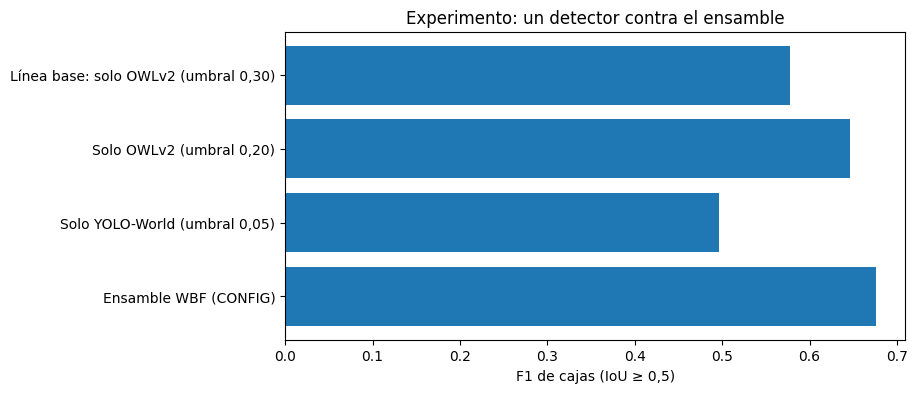

In [22]:
plt.figure(figsize=(8, 4))
plt.barh(df_experimento.variante, df_experimento.f1)
plt.xlabel("F1 de cajas (IoU ≥ 0,5)")
plt.title("Experimento: un detector contra el ensamble")
plt.gca().invert_yaxis()
plt.show()

## Pipeline completa sobre desarrollo y métricas finales
Con la configuración elegida corremos la pipeline completa (detección, SAM2 y SceneJSON) sobre las 120 imágenes de desarrollo, guardamos cada escena en `escenas_dev/` y calculamos el F1 de cajas y de máscaras. Las métricas se guardan junto con la configuración en `metricas_dev.json`.

In [23]:
escenas_dev = {}
for ruta in IMAGENES_DEV:
    escenas_dev[id_desde_ruta(ruta)] = procesar_imagen(ruta, crudos_dev[ruta])

os.makedirs("escenas_dev", exist_ok=True)
for image_id, escena in escenas_dev.items():
    with open(f"escenas_dev/{image_id}.json", "w") as f:
        json.dump(escena, f)

metricas = {
    "cajas": resumir([evaluar_imagen(e) for e in escenas_dev.values()]),
    "mascaras": resumir([evaluar_imagen(e, usar_mascaras=True) for e in escenas_dev.values()]),
}
with open("metricas_dev.json", "w") as f:
    json.dump({"config": CONFIG, "metricas": metricas}, f, indent=2)
display(pd.DataFrame(metricas).T)

,tp,fp,fn,ignoradas,precision,recall,f1,cobertura
cajas,1093.0,353.0,697.0,2231.0,0.7559,0.6106,0.6755,0.3933
mascaras,1036.0,403.0,754.0,2238.0,0.7199,0.5788,0.6417,0.3914


## Atributos y relaciones
Además de encontrar los objetos, queremos saber si sus propiedades son correctas. Para cada objeto predicho que coincide con uno anotado (misma clase e IoU de al menos 0,5):

- **Posición y tamaño:** comparamos los valores calculados con nuestra máscara contra los calculados con la máscara real.
- **Relaciones:** calculamos las relaciones reales con las mismas reglas entre los objetos emparejados y medimos qué parte de nuestras relaciones son correctas (precisión) y qué parte de las reales encontramos (recall).

Después validamos todas las escenas contra `scene_schema.json`, que es lo que mide la parte de "consistencia del JSON" en la competencia.

In [24]:
# [logica]
def emparejar(escena, iou_min=0.5):
    """Pares (objeto predicho, anotación GT) de la misma clase con IoU de caja >= iou_min."""
    info = lvis_gt.imgs[ARCHIVO_A_ID[escena["image"]["file_name"]]]
    libres = lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[info["id"]]))
    pares = []
    for obj in sorted(escena["objects"], key=lambda o: -o["confidence"]):
        candidatos = [a for a in libres if a["category_id"] == obj["category_id"] and iou_cajas(xyxy_a_xywh(obj["bbox"]), a["bbox"]) >= iou_min]
        if candidatos:
            mejor = max(candidatos, key=lambda a: iou_cajas(xyxy_a_xywh(obj["bbox"]), a["bbox"]))
            libres.remove(mejor)
            pares.append((obj, mejor))
    return pares

def propiedades_gt(ann):
    mascara = mascara_gt(ann)
    h, w = mascara.shape
    ys, xs = np.nonzero(mascara)
    cx, cy = xs.mean() / w, ys.mean() / h
    return {"centroid_norm": [cx, cy], "position": posicion_grilla(cx, cy), "size": tamano_relativo(mascara.sum() / (h * w))}

def evaluar_atributos_y_relaciones(escena):
    pares = emparejar(escena)
    r = {"pares": len(pares), "posicion_ok": 0, "tamano_ok": 0, "rel_tp": 0, "rel_pred": 0, "rel_gt": 0}
    gt_objs = []
    for obj, ann in pares:
        gt = propiedades_gt(ann)
        r["posicion_ok"] += obj["position"] == gt["position"]
        r["tamano_ok"] += obj["size"] == gt["size"]
        gt_objs.append({"id": obj["id"], "centroid_norm": gt["centroid_norm"]})
    ids = {obj["id"] for obj, _ in pares}
    pred = {(x["subject"], x["predicate"], x["object"]) for x in escena["relations"] if x["subject"] in ids and x["object"] in ids}
    mascaras = [mascara_gt(ann) for _, ann in pares]
    gt_rel = {(x["subject"], x["predicate"], x["object"]) for x in relaciones(gt_objs, mascaras)}
    r["rel_tp"], r["rel_pred"], r["rel_gt"] = len(pred & gt_rel), len(pred), len(gt_rel)
    return r

In [25]:
tot = pd.DataFrame([evaluar_atributos_y_relaciones(e) for e in escenas_dev.values()]).sum()
metricas["atributos"] = {
    "objetos_emparejados": int(tot.pares),
    "acierto_posicion": round(tot.posicion_ok / tot.pares, 4),
    "acierto_tamano": round(tot.tamano_ok / tot.pares, 4),
    "precision_relaciones": round(tot.rel_tp / tot.rel_pred, 4) if tot.rel_pred else 0,
    "recall_relaciones": round(tot.rel_tp / tot.rel_gt, 4) if tot.rel_gt else 0,
}
with open("metricas_dev.json", "w") as f:
    json.dump({"config": CONFIG, "metricas": metricas}, f, indent=2)
print(json.dumps(metricas["atributos"], indent=2))

{
  "objetos_emparejados": 1093,
  "acierto_posicion": 0.9762,
  "acierto_tamano": 0.957,
  "precision_relaciones": 0.9825,
  "recall_relaciones": 0.9731
}


In [26]:
# Validación del SceneJSON contra el schema oficial (consistencia de la representación)
import jsonschema

if RUTA_SCHEMA:
    schema = json.load(open(RUTA_SCHEMA))
    errores = {}
    for image_id, escena in escenas_dev.items():
        try:
            jsonschema.validate(escena, schema)
        except jsonschema.ValidationError as e:
            errores[image_id] = e.message
    print(f"Escenas válidas: {len(escenas_dev) - len(errores)} de {len(escenas_dev)}")
    for image_id, msg in list(errores.items())[:5]:
        print(image_id, "->", msg)
else:
    print("No se encontró scene_schema.json: agregar los datos de la competencia como input.")

Escenas válidas: 120 de 120


# 9. Preguntas y respuestas (modo determinista)
Las preguntas se contestan con **código, sin LLM**, leyendo solo el SceneJSON. Así, cada respuesta es reproducible y se puede justificar con los objetos que la sustentan (`evidence`).

El motor recibe una **consulta estructurada** (qué operación hacer y sobre qué clases):

| Operación | Clases que recibe | Responde |
|---|---|---|
| `count` | 1 | Cuántos objetos hay |
| `existence` | 1 | *yes* / *no* |
| `position` | 1 | En cuál de las 9 regiones está |
| `size` | 1 | *small* / *medium* / *large* |
| `relation` | 2 + relación | *yes* / *no* |
| `color` | 1 | Nombre del color (extra) |
| `compare_count` | 2 | *yes* / *no*: ¿hay más del primero que del segundo? (extra) |

**Casos especiales, para no inventar respuestas:**

- **`unsupported`:** la clase no está entre las 120, la operación no existe o la relación no es una de las que sabemos calcular: las cinco del schema (`left_of`, `right_of`, `above`, `below`, `overlaps`) más `near`, que derivamos de la distancia entre centroides (menos de `distancia_cerca`) o de que las máscaras se toquen. Por ejemplo, *on* o *behind* no se soportan.
- **Nombres de clase:** se comparan sin tildes y tratando igual espacios y guiones bajos (`wall socket` = `wall_socket`), además de los sinónimos de LVIS.
- **`insufficient_information`:** se pregunta la posición, el tamaño o el color de un objeto que no se detectó, o una relación en la que falta alguno de los dos objetos.
- **Ambigüedad:** si hay varios objetos de la clase, se usa el de mayor confianza y se baja la confianza de la respuesta.

Las preguntas de `questions_dev.jsonl` ya traen la operación y las clases. La relación se reconoce en el texto buscando frases fijas como "a la izquierda de".

In [27]:
# [logica]
import re, unicodedata

# Las primeras cinco son los tipos del benchmark; color y compare_count son extras nuestros.
OPERACIONES = {"count": 1, "existence": 1, "position": 1, "size": 1, "relation": 2, "color": 1, "compare_count": 2}
RELACIONES = {"left_of", "right_of", "above", "below", "overlaps", "near"}   # los del schema + near (derivada)

def clave(texto):
    """Forma comparable de un nombre: minúsculas, sin tildes, con espacios en lugar de guiones bajos."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower()
    t = re.sub(r"[_\-]+", " ", t)
    t = re.sub(r"[^a-z0-9() ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# Sinónimos de cada clase (vienen en la definición de categorías de LVIS), p. ej. "cell_phone" -> "cellular_telephone"
# Las claves se comparan con clave(), así "wall socket", "wall_socket" y "Wall-Socket" son lo mismo.
SINONIMOS = {clave(sin): c["name"] for c in datos_lvis["categories"] for sin in c.get("synonyms", [])}
SINONIMOS.update({clave(c["name"]): c["name"] for c in datos_lvis["categories"]})   # el nombre oficial manda

def normalizar_clase(texto):
    """Lleva un nombre libre a una clase del vocabulario (sin tildes, espacios o guiones bajos, sinónimos y plurales simples)."""
    if texto is None:
        return None
    t = clave(texto)
    for candidato in [t, t[:-1] if t.endswith("s") else t, t[:-2] if t.endswith("es") else t]:
        if candidato in SINONIMOS:
            return SINONIMOS[candidato]
    return None

def objetos_de(escena, clase):
    return [o for o in escena["objects"] if o["category"] == clase]

def hay_relacion(escena, a, predicado, b):
    return any(r["predicate"] == predicado and r["subject"] == a and r["object"] == b for r in escena["relations"])

def cumple_relacion(escena, a, predicado, b):
    """near no está en el schema: se deriva de los centroides (o de que las máscaras se toquen)."""
    if predicado == "near":
        (ax, ay), (bx, by) = a["centroid_norm"], b["centroid_norm"]
        distancia = ((ax - bx) ** 2 + (ay - by) ** 2) ** 0.5
        return distancia < CONFIG.get("distancia_cerca", 0.25) or hay_relacion(escena, a["id"], "overlaps", b["id"])
    return hay_relacion(escena, a["id"], predicado, b["id"])

def respuesta(normalizada, evidencia, confianza, texto=None):
    return {"answer": texto if texto is not None else str(normalizada), "normalized_answer": normalizada,
            "evidence": evidencia, "confidence": round(float(confianza), 3)}

def confianza_de(objs):
    return np.mean([o["confidence"] for o in objs]) if objs else 0.5   # sin evidencia no podemos asegurar la ausencia

def ejecutar_consulta(escena, consulta):
    op = consulta.get("op")
    if op not in OPERACIONES:
        return respuesta("unsupported", [], 1.0)
    clases = [normalizar_clase(o) for o in consulta.get("objects", [])]
    if len(clases) != OPERACIONES[op] or None in clases:
        return respuesta("unsupported", [], 1.0)
    objs = objetos_de(escena, clases[0])
    ids = [o["id"] for o in objs]

    if op == "count":
        return respuesta(len(objs), ids, confianza_de(objs))
    if op == "existence":
        return respuesta("yes" if objs else "no", ids, confianza_de(objs))
    if op in ("position", "size", "color"):
        if not objs:
            return respuesta("insufficient_information", [], 1.0)
        principal = max(objs, key=lambda o: o["confidence"])
        confianza = principal["confidence"] / len(objs)   # varios candidatos = respuesta ambigua
        return respuesta(principal[op], [principal["id"]], confianza)
    if op == "compare_count":
        otros = objetos_de(escena, clases[1])
        return respuesta("yes" if len(objs) > len(otros) else "no", ids + [o["id"] for o in otros], confianza_de(objs + otros))
    if op == "relation":
        predicado = consulta.get("relation")
        if predicado not in RELACIONES:
            return respuesta("unsupported", [], 1.0)
        otros = objetos_de(escena, clases[1])
        if not objs or not otros:
            return respuesta("insufficient_information", ids + [o["id"] for o in otros], 1.0)
        for a in objs:
            for b in otros:
                if a["id"] != b["id"] and cumple_relacion(escena, a, predicado, b):
                    return respuesta("yes", [a["id"], b["id"]], min(a["confidence"], b["confidence"]))
        return respuesta("no", ids + [o["id"] for o in otros], confianza_de(objs + otros))

def describir_determinista(escena):
    if not escena["objects"]:
        return "No se detectaron objetos en la imagen."
    conteo = Counter(o["category"] for o in escena["objects"])
    partes = [f"{n} x {clase.replace('_', ' ')}" for clase, n in conteo.most_common()]
    return "En la escena se detectaron: " + ", ".join(partes) + "."

In [28]:
# Cada pregunta de questions_dev.jsonl trae: type (la operación), class_en (las clases) y el texto.
# La relación no viene como campo: se reconoce en el texto con reglas fijas (sin LLM).
FRASES_RELACION = {"por encima de": "above", "por debajo de": "below",
                   "a la izquierda de": "left_of", "a la derecha de": "right_of", "se superpone": "overlaps"}

def relacion_desde_texto(texto):
    for frase, predicado in FRASES_RELACION.items():
        if frase in texto.lower():
            return predicado
    return None

def pregunta_a_consulta(pregunta):
    return {"op": pregunta["type"],
            "objects": pregunta.get("class_en", []),
            "relation": relacion_desde_texto(pregunta["question"]) if pregunta["type"] == "relation" else None}

def responder_determinista(escena, pregunta):
    base = {k: pregunta[k] for k in ["question_id", "type", "question"]}
    if pregunta["type"] == "description":
        texto = describir_determinista(escena)
        base.update(respuesta(texto, [o["id"] for o in escena["objects"]], 1.0, texto))
        return base
    base.update(respuesta_con_traza(escena, pregunta_a_consulta(pregunta), "pregunta_determinista"))
    return base

def respuesta_con_traza(escena, consulta, etapa):
    return traza.etapa(escena["image"]["id"], etapa, lambda: ejecutar_consulta(escena, consulta), consulta) \
        or respuesta("unsupported", [], 1.0)

preguntas_por_imagen = defaultdict(list)
with open(RUTA_PREGUNTAS) as f:
    preguntas = [json.loads(linea) for linea in f if linea.strip()]
print("Ejemplo de pregunta:", json.dumps(preguntas[1], indent=2, ensure_ascii=False))
for p in preguntas:
    preguntas_por_imagen[os.path.splitext(p["image_file"])[0]].append(p)
print("Preguntas:", len(preguntas), "| imágenes con preguntas:", len(preguntas_por_imagen))
print(Counter(p["type"] for p in preguntas))

# Chequeo: todas las clases de las preguntas tienen que existir en nuestro vocabulario
sin_mapear = {c for p in preguntas for c in p["class_en"] if normalizar_clase(c) is None}
print("Clases de las preguntas que no reconocemos:", sin_mapear or "ninguna")

for image_id, lista in preguntas_por_imagen.items():
    escenas_dev[image_id]["questions"] = [responder_determinista(escenas_dev[image_id], p) for p in lista]

Ejemplo de pregunta: {
  "schema_version": "1.0",
  "question_id": "DEV-1-Q1",
  "image_id": 1,
  "image_file": "tpi_0001.jpg",
  "type": "count",
  "question": "¿Cuántas instancias de la categoría \"pomo de puerta\" aparecen en la imagen?",
  "answer_format": "integer",
  "class_en": [
    "doorknob"
  ],
  "class_es": [
    "pomo de puerta"
  ]
}
Preguntas: 60 | imágenes con preguntas: 20
Counter({'description': 20, 'count': 10, 'existence': 10, 'relation': 10, 'position': 5, 'size': 5})
Clases de las preguntas que no reconocemos: ninguna


## ¿Las respuestas están sustentadas por el JSON?
Comprobamos dos cosas:

1. **Fidelidad:** que los objetos citados como evidencia existan en el SceneJSON y que, en conteo y existencia, la cantidad de evidencia coincida con la respuesta.
2. **Origen de los errores:** corremos el mismo motor sobre una escena armada con las anotaciones reales (solo para evaluar). Si con las anotaciones la respuesta es correcta y con nuestra escena no, el error viene de la detección y no del motor de preguntas.

In [29]:
# [logica]
def verificar_fidelidad(escena, resp, op):
    ids = {o["id"] for o in escena["objects"]}
    if not set(resp["evidence"]) <= ids:
        return False
    if op == "count":
        return resp["normalized_answer"] == len(resp["evidence"])
    if op == "existence":
        return (resp["normalized_answer"] == "yes") == (len(resp["evidence"]) > 0)
    return True

def escena_desde_gt(file_name):
    """SOLO PARA EVALUAR: escena con los objetos anotados, sin máscaras ni relaciones de máscara."""
    info = lvis_gt.imgs[ARCHIVO_A_ID[file_name]]
    objetos = []
    for k, ann in enumerate(lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[info["id"]]))):
        x, y, w, h = ann["bbox"]
        cx, cy = (x + w / 2) / info["width"], (y + h / 2) / info["height"]
        area_rel = ann["area"] / (info["width"] * info["height"])
        objetos.append({"id": f"gt_{k}", "category": lvis_gt.cats[ann["category_id"]]["name"], "confidence": 1.0,
                        "centroid_norm": [cx, cy], "position": posicion_grilla(cx, cy),
                        "size": tamano_relativo(area_rel), "color": "unknown"})
    vacias = np.zeros((len(objetos), 1, 1), dtype=bool)
    return {"image": {"id": file_name, "file_name": file_name}, "objects": objetos,
            "relations": relaciones(objetos, vacias)}

In [30]:
filas = []
for image_id, lista in preguntas_por_imagen.items():
    escena = escenas_dev[image_id]
    escena_gt = escena_desde_gt(escena["image"]["file_name"])
    for p, resp in zip(lista, escena["questions"]):
        if p["type"] == "description":
            continue
        consulta = pregunta_a_consulta(p)
        filas.append({"image_id": image_id, "question_id": p["question_id"], "type": p["type"],
                      "respuesta": resp["normalized_answer"],
                      "respuesta_con_gt": ejecutar_consulta(escena_gt, consulta)["normalized_answer"],
                      "fiel_al_json": verificar_fidelidad(escena, resp, consulta["op"])})
df_preguntas = pd.DataFrame(filas)
if len(df_preguntas):
    df_preguntas["coincide_con_gt"] = df_preguntas.respuesta.astype(str) == df_preguntas.respuesta_con_gt.astype(str)
    df_preguntas.to_csv("evaluacion_preguntas_determinista.csv", index=False)
    print("Respuestas fieles al JSON:", df_preguntas.fiel_al_json.mean().round(3))
    display(df_preguntas.groupby("type")[["coincide_con_gt", "fiel_al_json"]].mean().round(3))

Respuestas fieles al JSON: 1.0


,coincide_con_gt,fiel_al_json
type,,
count,0.5,1.0
existence,0.9,1.0
position,0.8,1.0
relation,0.8,1.0
size,0.6,1.0


# 10. Preguntas con LLM (promoción)
Usamos **Qwen2.5-1.5B-Instruct**, un modelo de lenguaje chico que entra en la GPU de Kaggle. El LLM **nunca ve la imagen, nunca calcula la respuesta y nunca recibe los campos estructurados de la pregunta** (`type`, `class_en`, `class_es`, `answer_format`). Lo único que recibe de cada pregunta es su texto (`question`).

La sección está separada en cuatro etapas, cada una con su propia función y su registro en la traza:

| Etapa | Qué hace | Quién lo hace |
|---|---|---|
| **A. Preprocesamiento** | Busca en el texto los objetos mencionados (lo que está entre comillas o, si no hay comillas, frases conocidas) y los lleva a una de las 120 clases con un glosario español → inglés, los sinónimos de LVIS y `difflib` para errores de tipeo. También junta las clases que hay en el SceneJSON de la imagen (`local_candidates`). | Código |
| **B. Interpretación** | `RobustLLMQueryInterpreter` le pide al LLM un único JSON (`interpreted_query`) con un prompt estricto y ejemplos inventados (ninguno sale del benchmark). | LLM |
| **C. Validación** | El JSON se parsea con tolerancia a errores de formato y se valida campo por campo. Los *guardrails* comparan con lo que dice el texto: si la pregunta tiene una frase explícita ("¿Cuántas…", "a la izquierda de…") o un objeto entre comillas y el LLM dice otra cosa, se corrige y queda registrado. Si el LLM no devuelve nada usable, se usa un intérprete de reglas como respaldo. Si no se puede armar una consulta válida, la respuesta es `unsupported`. | Código |
| **D. Ejecución** | El **mismo motor determinista de la sección 9** (`ejecutar_consulta`) calcula `normalized_answer` y `evidence` sobre el SceneJSON. El LLM solo redacta `answer` a partir del resultado ya calculado, y se verifica que la redacción no lo contradiga. | Código (+ LLM para redactar) |

**El JSON intermedio** tiene siempre estas cinco claves:

```json
{"type": "count | existence | position | size | color | compare_count | spatial_relation | description | unsupported",
 "target_category": "clase o null", "reference_category": "clase o null",
 "relation": "left_of | right_of | above | below | near | overlaps | null",
 "attribute": "position | size | color | null"}
```

`color` y `compare_count` son las operaciones extra del motor de la sección 9, y `overlaps` es el predicado del schema que falta en la lista base.

**Respuestas normalizadas:** conteo como texto (`"0"`, `"2"`), `yes`/`no` para existencia, relaciones y comparación, una de las 9 regiones para posición, `small`/`medium`/`large` para tamaño, y `unsupported` cuando la pregunta está fuera de alcance, es ambigua o el SceneJSON no tiene la información (por ejemplo, la posición de un objeto que no se detectó).

**Descripciones:** el LLM recibe solo una lista de hechos sacados del SceneJSON. Si su texto nombra una clase que no está en la escena, se descarta y se usa la descripción por plantilla.

Todo lo que pasa en las etapas A a C (texto crudo del LLM, errores, correcciones) se guarda en `interpretaciones_llm.jsonl`, y al final comparamos el **LLM solo** contra el **LLM con guardrails** (comparación controlada).

In [31]:
from transformers import AutoTokenizer, AutoModelForCausalLM

# Liberamos memoria de la GPU antes de cargar el LLM (OWLv2 se vuelve a cargar en la sección 11)
if 'modelo_det' in globals():
    del modelo_det
if torch.cuda.is_available():
    torch.cuda.empty_cache()

try:
    tok_llm = AutoTokenizer.from_pretrained(CONFIG["llm"])
    modelo_llm = AutoModelForCausalLM.from_pretrained(
        CONFIG["llm"], dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
    LLM_DISPONIBLE = True
except Exception as e:   # sin LLM la sección sigue con el intérprete de reglas y queda registrado
    print("No se pudo cargar el LLM:", repr(e))
    tok_llm, modelo_llm, LLM_DISPONIBLE = None, None, False
print("LLM disponible:", LLM_DISPONIBLE)

def generar_llm(mensajes, max_tokens=None):
    """Recibe una conversación [{"role": ..., "content": ...}] y devuelve el texto que genera el LLM."""
    if not LLM_DISPONIBLE:
        return ""
    try:
        prompt = tok_llm.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    except Exception:   # formato de chat de Qwen escrito a mano, por si el tokenizer no trae plantilla
        prompt = "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in mensajes) + "<|im_start|>assistant\n"
    entrada = tok_llm(prompt, return_tensors="pt").to(device)
    temperatura = CONFIG["llm_temperatura"]
    opciones = {"do_sample": True, "temperature": temperatura, "top_p": 1.0, "top_k": 0} if temperatura > 0 else {"do_sample": False}
    torch.manual_seed(SEMILLA)   # misma semilla en cada llamada: la salida no depende del orden de las preguntas
    with torch.no_grad():
        salida = modelo_llm.generate(**entrada, max_new_tokens=max_tokens or CONFIG["llm_max_tokens"],
                                     repetition_penalty=1.0, pad_token_id=tok_llm.eos_token_id, **opciones)
    return tok_llm.decode(salida[0][entrada["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def preguntar_llm(sistema, usuario, max_tokens=150):
    return generar_llm([{"role": "system", "content": sistema}, {"role": "user", "content": usuario}], max_tokens)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM disponible: True


## A. Preprocesamiento de la pregunta
`canonizar_entidad` lleva un nombre libre a una de las 120 clases probando, en orden: el nombre o un sinónimo de LVIS, el glosario español → inglés y el inglés coloquial (`couch` → `sofa`, `tv` → `television set`), plurales simples y, por último, `difflib.get_close_matches` con un corte alto (`fuzzy_corte`) para no confundir clases. Las reglas de texto (`reglas_desde_texto`) reconocen frases explícitas como "¿Cuántas…" o "a la izquierda de"; no deciden solas, sirven para controlar al LLM.

In [32]:
# [logica]
# A. Preprocesamiento: llevar los nombres de objetos del texto a clases del vocabulario
import difflib

# Glosario general español -> nombres posibles en inglés. Es una traducción del vocabulario de objetos
# comunes (no usa los campos de las preguntas). Solo se usan las entradas que llegan a una de las 120 clases.
GLOSARIO_ES = {
    "persona": ["person"], "personas": ["person"], "gente": ["person"], "hombre": ["person"], "mujer": ["person"],
    "nino": ["person"], "nina": ["person"], "chico": ["person"], "chica": ["person"], "jugador": ["person"],
    "perro": ["dog"], "gato": ["cat"], "caballo": ["horse"], "vaca": ["cow"], "oveja": ["sheep"], "pajaro": ["bird"],
    "elefante": ["elephant"], "jirafa": ["giraffe"], "cebra": ["zebra"], "oso": ["bear"], "oso de peluche": ["teddy bear"],
    "auto": ["car", "car (automobile)"], "coche": ["car", "car (automobile)"], "carro": ["car", "car (automobile)"],
    "camion": ["truck"], "colectivo": ["bus", "bus (vehicle)"], "autobus": ["bus", "bus (vehicle)"], "omnibus": ["bus", "bus (vehicle)"],
    "bicicleta": ["bicycle"], "moto": ["motorcycle"], "motocicleta": ["motorcycle"], "avion": ["airplane"], "tren": ["train", "train (railroad vehicle)"],
    "barco": ["boat"], "bote": ["boat"], "semaforo": ["traffic light"], "rueda": ["wheel"], "neumatico": ["tire"],
    "matricula": ["license plate"], "patente": ["license plate"], "espejo retrovisor": ["rearview mirror"],
    "silla": ["chair"], "sofa": ["sofa"], "sillon": ["armchair", "sofa"], "banco": ["bench"], "taburete": ["stool"],
    "mesa": ["table", "dining table"], "mesa de comedor": ["dining table"], "escritorio": ["desk"], "cama": ["bed"],
    "almohada": ["pillow"], "almohadon": ["cushion", "pillow"], "cojin": ["cushion"], "manta": ["blanket"], "frazada": ["blanket"],
    "cortina": ["curtain"], "alfombra": ["rug", "carpet"], "lampara": ["lamp"], "cuadro": ["picture", "painting"],
    "marco": ["frame", "picture frame"], "estante": ["shelf"], "repisa": ["shelf"], "armario": ["cabinet", "cupboard"],
    "cajon": ["drawer"], "puerta": ["door"], "ventana": ["window"], "pomo de puerta": ["doorknob", "knob"],
    "picaporte": ["doorknob", "door handle"], "manija": ["handle", "doorknob"], "mango": ["handle"],
    "tomacorriente": ["wall socket", "outlet"], "enchufe": ["wall socket", "plug"], "interruptor": ["light switch", "switch"],
    "toalla": ["towel"], "inodoro": ["toilet"], "lavabo": ["sink"], "lavamanos": ["sink"], "pileta": ["sink"], "fregadero": ["sink"],
    "grifo": ["faucet"], "canilla": ["faucet"], "espejo": ["mirror"], "jabon": ["soap"], "papel higienico": ["toilet tissue"],
    "maceta": ["flowerpot"], "planta": ["plant", "potted plant"], "flor": ["flower"], "florero": ["vase"], "jarron": ["vase"],
    "reloj": ["clock"], "reloj de pared": ["clock", "wall clock"], "reloj de pulsera": ["watch", "wristwatch"],
    "televisor": ["television set", "tv"], "television": ["television set", "tv"], "tele": ["television set", "tv"],
    "computadora": ["computer", "laptop"], "computadora portatil": ["laptop", "laptop computer"], "notebook": ["laptop"],
    "portatil": ["laptop"], "monitor": ["monitor", "monitor (computer equipment) computer monitor"],
    "teclado": ["computer keyboard", "keyboard"], "teclado de computadora": ["computer keyboard"],
    "mouse": ["computer mouse", "mouse (computer equipment)"], "raton": ["computer mouse", "mouse (computer equipment)"],
    "mouse de computadora": ["computer mouse", "mouse (computer equipment)"], "control remoto": ["remote control"],
    "telefono": ["telephone", "cell phone"], "celular": ["cell phone", "cellular telephone"],
    "telefono celular": ["cell phone", "cellular telephone"], "telefono movil": ["cell phone", "cellular telephone"],
    "auriculares": ["headphone", "earphone"], "camara": ["camera"], "libro": ["book"], "cuaderno": ["notebook"],
    "lapiz": ["pencil"], "lapicera": ["pen"], "boligrafo": ["pen"], "tijera": ["scissors"], "tijeras": ["scissors"],
    "papel": ["paper"], "sobre": ["envelope"], "caja": ["box"], "carton": ["carton", "box"], "bolsa": ["bag"],
    "bolsa de plastico": ["plastic bag"], "bolsa de papel": ["paper bag"], "bolso": ["handbag"], "cartera": ["handbag"],
    "mochila": ["backpack"], "valija": ["suitcase"], "maleta": ["suitcase"], "paraguas": ["umbrella"], "sombrilla": ["umbrella"],
    "camisa": ["shirt"], "remera": ["t-shirt", "shirt"], "camiseta": ["jersey", "t-shirt", "shirt"], "chaqueta": ["jacket"],
    "campera": ["jacket"], "abrigo": ["coat"], "sueter": ["sweater"], "buzo": ["sweatshirt"], "vestido": ["dress"],
    "falda": ["skirt"], "pollera": ["skirt"], "pantalon": ["trousers"], "pantalones": ["trousers"], "short": ["shorts"],
    "pantalones cortos": ["shorts"], "jean": ["jean", "jeans"], "jeans": ["jean", "jeans"], "vaqueros": ["jean", "jeans"],
    "zapato": ["shoe"], "zapatilla": ["shoe", "sneaker"], "bota": ["boot"], "sandalia": ["sandal"], "calcetin": ["sock"],
    "media": ["sock"], "medias": ["sock"], "sombrero": ["hat"], "gorra": ["cap", "baseball cap"], "gorro": ["hat", "cap"],
    "gorra de beisbol": ["baseball cap"], "casco": ["helmet"], "corbata": ["necktie", "tie"], "cinturon": ["belt"],
    "guante": ["glove"], "guantes": ["glove"], "guante de beisbol": ["baseball glove"], "bufanda": ["scarf"],
    "gafas": ["spectacles", "glasses", "eyeglasses"], "anteojos": ["spectacles", "glasses"], "lentes": ["spectacles", "glasses"],
    "gafas de sol": ["sunglasses"], "anteojos de sol": ["sunglasses"], "collar": ["necklace"], "anillo": ["ring"],
    "pulsera": ["bracelet"], "arete": ["earring"], "aro": ["earring"], "correa": ["strap"], "tira": ["strap"],
    "botella": ["bottle"], "vaso": ["cup", "glass", "drinking glass"], "copa": ["wineglass", "wine glass"], "taza": ["cup", "mug"],
    "jarra": ["pitcher", "jug"], "plato": ["plate"], "cuenco": ["bowl"], "bol": ["bowl"], "tazon": ["bowl"],
    "tenedor": ["fork"], "cuchillo": ["knife"], "cuchara": ["spoon"], "servilleta": ["napkin"], "mantel": ["tablecloth"],
    "bandeja": ["tray"], "olla": ["pot"], "sarten": ["frying pan"], "lata": ["can"], "frasco": ["jar"],
    "heladera": ["refrigerator"], "refrigerador": ["refrigerator"], "nevera": ["refrigerator"], "horno": ["oven"],
    "microondas": ["microwave oven"], "tostadora": ["toaster"], "pizza": ["pizza"], "torta": ["cake"], "pastel": ["cake"],
    "sandwich": ["sandwich"], "banana": ["banana"], "platano": ["banana"], "manzana": ["apple"], "naranja": ["orange", "orange (fruit)"],
    "zanahoria": ["carrot"], "brocoli": ["broccoli"], "tomate": ["tomato"], "limon": ["lemon"], "pan": ["bread"],
    "rosquilla": ["doughnut", "donut"], "dona": ["doughnut", "donut"], "pelota": ["ball"], "balon": ["ball"],
    "pelota de futbol": ["soccer ball"], "pelota de tenis": ["tennis ball"], "raqueta": ["tennis racket"],
    "raqueta de tenis": ["tennis racket"], "bate": ["baseball bat"], "bate de beisbol": ["baseball bat"],
    "patineta": ["skateboard"], "monopatin": ["skateboard"], "tabla de surf": ["surfboard"], "esqui": ["ski"], "esquis": ["ski"],
    "tabla de snowboard": ["snowboard"], "barrilete": ["kite"], "cometa": ["kite"], "frisbee": ["frisbee"],
    "cartel": ["signboard", "sign"], "letrero": ["signboard", "sign"], "senal": ["street sign", "signboard"],
    "pancarta": ["banner"], "bandera": ["flag"], "toldo": ["awning"], "farol": ["streetlight", "lamppost"],
    "poste": ["pole", "post"], "cerca": ["fence"], "valla": ["fence"], "edificio": ["building"], "arbol": ["tree"],
    "hidrante": ["fire hydrant"], "boca de incendio": ["fire hydrant"], "banco de plaza": ["bench"], "cubo de basura": ["trash can"],
    "tacho de basura": ["trash can"], "papelera": ["trash can"], "cesto": ["basket"], "canasta": ["basket"],
    "vela": ["candle"], "cepillo de dientes": ["toothbrush"], "secador de pelo": ["hair drier", "hair dryer"],
    "ventilador": ["fan"], "aire acondicionado": ["air conditioner"], "radiador": ["radiator"], "estufa": ["stove"],
    "juguete": ["toy"], "muneca": ["doll"], "globo": ["balloon"], "chaleco": ["vest"], "delantal": ["apron"],
    "etiqueta": ["label", "tag"], "pegatina": ["sticker"], "calcomania": ["sticker"], "logo": ["logo"],
}

# Inglés coloquial -> nombres posibles del vocabulario (lo que suele escribir un LLM)
ALIAS_EN = {
    "couch": ["sofa"], "people": ["person"], "man": ["person"], "woman": ["person"], "men": ["person"], "women": ["person"],
    "child": ["person"], "kid": ["person"], "boy": ["person"], "girl": ["person"], "player": ["person"],
    "tv": ["television set", "television"], "television": ["television set"], "tv set": ["television set"],
    "cellphone": ["cell phone", "cellular telephone"], "mobile phone": ["cell phone", "cellular telephone"],
    "smartphone": ["cell phone", "cellular telephone"], "phone": ["cell phone", "telephone"],
    "laptop computer": ["laptop"], "notebook computer": ["laptop"], "mouse": ["computer mouse", "mouse (computer equipment)"],
    "keyboard": ["computer keyboard"], "fridge": ["refrigerator"], "glasses": ["spectacles", "eyeglasses"],
    "eyeglasses": ["spectacles"], "jeans": ["jean"], "pants": ["trousers"], "cap": ["baseball cap"],
    "purse": ["handbag"], "bag": ["handbag", "bag"], "outlet": ["wall socket"], "socket": ["wall socket"],
    "power outlet": ["wall socket"], "electrical outlet": ["wall socket"], "sign": ["signboard"],
    "flower pot": ["flowerpot"], "plant pot": ["flowerpot"], "knob": ["doorknob"], "door knob": ["doorknob"],
    "door handle": ["doorknob"], "racket": ["tennis racket"], "racquet": ["tennis racket"], "mitt": ["baseball glove"],
    "wristwatch": ["watch"], "cup": ["cup", "mug"], "car": ["car (automobile)"], "bike": ["bicycle"],
    "motorbike": ["motorcycle"], "plane": ["airplane"], "trash bin": ["trash can"], "garbage can": ["trash can"],
    "skate board": ["skateboard"], "surf board": ["surfboard"], "table cloth": ["tablecloth"], "t shirt": ["t-shirt"],
}

VOCAB_POR_CLAVE = {clave(n): n for n in VOCABULARIO}
ARTICULOS = {"el", "la", "los", "las", "un", "una", "unos", "unas", "the", "a", "an", "de", "del"}

def variantes(k):
    """La clave tal cual y con plurales simples (en la primera y en la última palabra)."""
    salida = [k]
    palabras = k.split()
    for i in {0, len(palabras) - 1} if palabras else set():
        p = palabras[i]
        for corte in ("es", "s"):
            if len(p) > 3 and p.endswith(corte):
                salida.append(" ".join(palabras[:i] + [p[:-len(corte)]] + palabras[i + 1:]))
    return list(dict.fromkeys(salida))

def resolver_directo(texto):
    """Nombre del vocabulario si el texto es una clase o un sinónimo de LVIS (sin tolerancia a errores)."""
    for k in variantes(clave(texto)):
        if k in VOCAB_POR_CLAVE:
            return VOCAB_POR_CLAVE[k]
        if k in SINONIMOS and SINONIMOS[k] in VOCAB_POR_CLAVE.values():
            return SINONIMOS[k]
    return None

def armar_indice():
    """clave -> (clase, origen) con todos los nombres que sabemos llevar a una clase."""
    indice = {}
    for origen, tabla in (("glosario_es", GLOSARIO_ES), ("alias_en", ALIAS_EN)):
        for nombre, candidatos in tabla.items():
            destino = next((c for c in (resolver_directo(x) for x in candidatos) if c), None)
            if destino:
                indice[clave(nombre)] = (destino, origen)
    for k, nombre in SINONIMOS.items():
        if nombre in VOCABULARIO:
            indice[k] = (nombre, "sinonimo_lvis")
    for k, nombre in VOCAB_POR_CLAVE.items():
        indice[k] = (nombre, "vocabulario")   # el nombre oficial siempre gana
    return indice

INDICE_ENTIDADES = armar_indice()

def canonizar_entidad(texto):
    """(clase del vocabulario o None, método usado). Nunca lanza excepciones."""
    if not isinstance(texto, str) or not texto.strip():
        return None, "vacio"
    k = clave(texto)
    sin_articulos = " ".join(p for p in k.split() if p not in ARTICULOS) or k
    for candidato in (k, sin_articulos):
        for v in variantes(candidato):
            if v in INDICE_ENTIDADES:
                return INDICE_ENTIDADES[v][0], INDICE_ENTIDADES[v][1]
    parecidos = difflib.get_close_matches(sin_articulos, list(INDICE_ENTIDADES), n=1, cutoff=CONFIG["fuzzy_corte"])
    if parecidos:
        return INDICE_ENTIDADES[parecidos[0]][0], "fuzzy"
    return None, "fuera_de_vocabulario"

def escanear_entidades(texto):
    """Clases mencionadas en un texto libre (coincidencia exacta de frases de 1 a 4 palabras, sin fuzzy)."""
    palabras = clave(texto).split()
    encontradas, usadas = [], set()
    for largo in (4, 3, 2, 1):
        for i in range(len(palabras) - largo + 1):
            if usadas & set(range(i, i + largo)):
                continue
            frase = " ".join(palabras[i:i + largo])
            if largo == 1 and (frase in ARTICULOS or frase in {"sobre", "cerca", "media"}):
                continue   # palabras que en una pregunta casi nunca son un objeto
            for v in variantes(frase):
                if v in INDICE_ENTIDADES:
                    encontradas.append((i, frase, INDICE_ENTIDADES[v][0]))
                    usadas |= set(range(i, i + largo))
                    break
    return [(frase, clase) for _, frase, clase in sorted(encontradas)]

def extraer_menciones(texto):
    """Objetos que nombra la pregunta, en orden: primero lo que está entre comillas; si no hay, frases conocidas."""
    citas = re.findall(r'["“”«»]([^"“”«»]{1,60})["“”«»]', texto)
    if citas:
        return [dict(zip(("texto", "categoria", "metodo"), (c, *canonizar_entidad(c)))) for c in citas]
    return [{"texto": frase, "categoria": clase, "metodo": "escaneo"} for frase, clase in escanear_entidades(texto)]

# Reglas fijas sobre el texto (sin las partes entre comillas). Sirven de guardrail y de respaldo si el LLM falla.
PATRONES_TIPO = [
    ("description", r"\bdescrib"),
    ("count", r"\bcuant[oa]s\b|\bcantidad de\b|\bnumero de\b|\bhow many\b"),
    ("compare_count", r"\bhay mas\b|\bmas .+ que\b|\bmore .+ than\b"),
    ("color", r"\bcolor\b"),
    ("size", r"\btamano\b|\bque tan grande\b|\bhow big\b|\bsize\b"),
    ("position", r"\bque zona\b|\bque parte\b|\bque region\b|\bdonde\b|\bwhere\b"),
    ("existence", r"^hay\b|\bhay al menos\b|\bhay algun|\bexiste|\bis there\b|\bare there\b"),
]
FRASES_RELACION_ES = [
    ("a la izquierda de", "left_of"), ("a la derecha de", "right_of"), ("por encima de", "above"), ("encima de", "above"),
    ("arriba de", "above"), ("por debajo de", "below"), ("debajo de", "below"), ("abajo de", "below"),
    ("cerca de", "near"), ("junto a", "near"), ("al lado de", "near"), ("se superpone", "overlaps"), ("superpuest", "overlaps"),
    ("to the left of", "left_of"), ("left of", "left_of"), ("to the right of", "right_of"), ("right of", "right_of"),
    ("above", "above"), ("below", "below"), ("under", "below"), ("next to", "near"), ("close to", "near"), ("near", "near"),
]

def reglas_desde_texto(texto, menciones):
    sin_citas = clave(re.sub(r'["“”«»][^"“”«»]{1,60}["“”«»]', " X ", texto))
    tipo = next((t for t, patron in PATRONES_TIPO if re.search(patron, sin_citas)), None)
    relaciones_vistas = {r for frase, r in FRASES_RELACION_ES if frase in sin_citas}
    relacion = relaciones_vistas.pop() if len(relaciones_vistas) == 1 else None   # dos relaciones distintas = ambiguo
    if relacion and len(menciones) >= 2 and tipo in (None, "existence", "position"):
        tipo = "spatial_relation"
    if tipo == "compare_count" and len(menciones) < 2:
        tipo = None
    return {"tipo": tipo, "relacion": relacion}

def candidatos_locales(escena):
    return sorted({o["category"] for o in escena.get("objects", [])})

def preprocesar_pregunta(texto, escena):
    texto = str(texto or "")
    menciones = extraer_menciones(texto)
    return {"texto": texto, "menciones": menciones, "local_candidates": candidatos_locales(escena),
            "reglas": reglas_desde_texto(texto, menciones)}

## B y C. Intérprete LLM con validación y guardrails
El prompt de sistema fija el formato y los ejemplos van como turnos de conversación (funciona mejor con modelos chicos que ponerlos en un solo texto). Al LLM le pasamos el texto de la pregunta, las pistas de la etapa A y las clases detectadas en la imagen (`local_candidates`).

Orden de decisión: **1)** si el LLM devuelve un JSON válido y coherente con el texto, se usa tal cual (`fuente = llm`); **2)** si tiene errores de formato o contradice una frase explícita del texto, se corrige campo por campo y se anota cada corrección (`llm+guardrails`); **3)** si no devuelve ningún JSON, se usan las reglas (`reglas`); **4)** si con todo eso la consulta no queda completa, es `unsupported`. La confianza final se multiplica por 1; 0,85 o 0,7 según la fuente.

In [33]:
# [logica]
# B y C. Intérprete LLM con validación y guardrails
import ast

TIPOS_CONSULTA = ["count", "existence", "position", "size", "color", "compare_count", "spatial_relation", "description", "unsupported"]
RELACIONES_LLM = ["left_of", "right_of", "above", "below", "near", "overlaps"]
CAMPOS_NECESARIOS = {"count": ("target_category",), "existence": ("target_category",), "position": ("target_category",),
                     "size": ("target_category",), "color": ("target_category",),
                     "compare_count": ("target_category", "reference_category"),
                     "spatial_relation": ("target_category", "reference_category", "relation"),
                     "description": (), "unsupported": ()}
ATRIBUTO_DE_TIPO = {"position": "position", "size": "size", "color": "color"}
ALIAS_TIPO = {"relation": "spatial_relation", "spatial": "spatial_relation", "relationship": "spatial_relation",
              "exists": "existence", "exist": "existence", "presence": "existence", "counting": "count",
              "location": "position", "where": "position", "describe": "description", "scene_description": "description",
              "comparison": "compare_count", "compare": "compare_count", "none": "unsupported", "unknown": "unsupported"}
ALIAS_RELACION = {"left": "left_of", "to_the_left_of": "left_of", "right": "right_of", "to_the_right_of": "right_of",
                  "on_top_of": "above", "over": "above", "top": "above", "under": "below", "beneath": "below",
                  "underneath": "below", "bottom": "below", "next_to": "near", "close_to": "near", "beside": "near",
                  "nearby": "near", "overlap": "overlaps", "overlapping": "overlaps"}
INVERSA = {"left_of": "right_of", "right_of": "left_of", "above": "below", "below": "above", "near": "near", "overlaps": "overlaps"}
CONSULTA_VACIA = {"type": "unsupported", "target_category": None, "reference_category": None, "relation": None, "attribute": None}

SISTEMA_INTERPRETE = f"""You are a semantic parser. You translate ONE question (usually in Spanish) about an image into ONE JSON object.
You never answer the question, never count and never guess what is in the image.

Reply with exactly one JSON object with these 5 keys and nothing else (no markdown, no explanations):
{{"type": ..., "target_category": ..., "reference_category": ..., "relation": ..., "attribute": ...}}

- "type": one of {TIPOS_CONSULTA}.
  count = how many; existence = is there at least one; position = where in the image; size = how big;
  color = what color; compare_count = are there more A than B; spatial_relation = is A left_of/right_of/above/below/near B;
  description = describe the scene; unsupported = anything else (actions, emotions, text, ambiguous questions).
- "target_category": the first object of the question, as an English category name. Use the hints. null if none.
- "reference_category": the second object (only for spatial_relation and compare_count), else null.
- "relation": one of {RELACIONES_LLM} or null. "A está por encima de B" -> target A, reference B, relation above.
- "attribute": "position", "size", "color" or null."""

EJEMPLOS_INTERPRETE = [   # inventados: ninguno sale de questions_dev.jsonl
    ('¿Cuántas instancias de la categoría "perro" aparecen en la imagen?', ['"perro" -> dog'], ["chair", "dog", "person"],
     {"type": "count", "target_category": "dog", "reference_category": None, "relation": None, "attribute": None}),
    ('¿Hay al menos una instancia de la categoría "paraguas" en la imagen?', ['"paraguas" -> umbrella'], ["car", "person"],
     {"type": "existence", "target_category": "umbrella", "reference_category": None, "relation": None, "attribute": None}),
    ('¿La instancia de "taza" está a la izquierda de la instancia de "botella"?', ['"taza" -> cup', '"botella" -> bottle'], ["bottle", "cup"],
     {"type": "spatial_relation", "target_category": "cup", "reference_category": "bottle", "relation": "left_of", "attribute": None}),
    ('¿La instancia de "silla" está por debajo de la instancia de "lámpara"?', ['"silla" -> chair', '"lámpara" -> lamp'], ["chair", "lamp", "table"],
     {"type": "spatial_relation", "target_category": "chair", "reference_category": "lamp", "relation": "below", "attribute": None}),
    ('¿En qué zona de la imagen está la instancia de "auto"?', ['"auto" -> car'], ["car", "tree"],
     {"type": "position", "target_category": "car", "reference_category": None, "relation": None, "attribute": "position"}),
    ('¿Qué tamaño relativo tiene la instancia de "mesa"?', ['"mesa" -> table'], ["chair", "table"],
     {"type": "size", "target_category": "table", "reference_category": None, "relation": None, "attribute": "size"}),
    ("Describí brevemente la escena.", [], ["dog", "sofa"],
     {"type": "description", "target_category": None, "reference_category": None, "relation": None, "attribute": None}),
    ("¿Qué está pensando la persona?", ['"persona" -> person'], ["person"],
     {"type": "unsupported", "target_category": None, "reference_category": None, "relation": None, "attribute": None}),
]

def mensaje_usuario(texto, pistas, locales):
    return (f"Question: {texto}\n"
            f"Hints (mention -> category): {'; '.join(pistas) if pistas else 'none'}\n"
            f"Categories detected in this image: {', '.join(locales) if locales else 'none'}\n"
            f"JSON:")

def extraer_json(texto):
    """Primer objeto JSON balanceado del texto. Tolera markdown, comillas simples, None/True/False y comas de más."""
    if not isinstance(texto, str):
        return None
    texto = texto.replace("```json", "").replace("```", "")
    inicio = texto.find("{")
    while inicio != -1:
        nivel = 0
        for fin in range(inicio, len(texto)):
            nivel += {"{": 1, "}": -1}.get(texto[fin], 0)
            if nivel == 0:
                bloque = re.sub(r",\s*([}\]])", r"\1", texto[inicio:fin + 1])
                try:
                    valor = json.loads(bloque)
                except json.JSONDecodeError:
                    try:
                        valor = ast.literal_eval(re.sub(r"\bnull\b", "None", re.sub(r"\btrue\b", "True", re.sub(r"\bfalse\b", "False", bloque))))
                    except Exception:
                        valor = None
                if isinstance(valor, dict):
                    return valor
                break
        inicio = texto.find("{", inicio + 1)
    return None

def _texto_campo(valor):
    if isinstance(valor, list):   # el LLM a veces devuelve ["dog"] en lugar de "dog"
        valor = valor[0] if valor else None
    if isinstance(valor, dict):
        valor = next(iter(valor.values()), None)
    if valor is None or str(valor).strip().lower() in ("", "null", "none", "n/a"):
        return None
    return str(valor).strip()

def validar_interpretacion(salida):
    """Devuelve (consulta con las 5 claves y clases canónicas, lista de errores, ¿es válida?)."""
    if not isinstance(salida, dict):
        return dict(CONSULTA_VACIA), ["sin_json"], False
    errores = []
    tipo = clave(_texto_campo(salida.get("type")) or "").replace(" ", "_")
    tipo = ALIAS_TIPO.get(tipo, tipo)
    if tipo not in TIPOS_CONSULTA:
        errores.append(f"type_invalido:{salida.get('type')!r}")
        tipo = "unsupported"
    consulta = {"type": tipo, "target_category": None, "reference_category": None, "relation": None, "attribute": None}
    for campo in ("target_category", "reference_category"):
        crudo = _texto_campo(salida.get(campo))
        if crudo is not None:
            clase, metodo = canonizar_entidad(crudo)
            consulta[campo] = clase
            if clase is None:
                errores.append(f"{campo}_fuera_de_vocabulario:{crudo!r}")
    relacion = _texto_campo(salida.get("relation"))
    if relacion is not None:
        relacion = clave(relacion).replace(" ", "_")
        relacion = ALIAS_RELACION.get(relacion, relacion)
        if relacion in RELACIONES_LLM:
            consulta["relation"] = relacion
        else:
            errores.append(f"relation_invalida:{salida.get('relation')!r}")
    consulta = completar_consulta(consulta)
    faltan = [c for c in CAMPOS_NECESARIOS[consulta["type"]] if consulta[c] is None]
    if faltan:
        errores.append("faltan:" + ",".join(faltan))
    if consulta["type"] in ("spatial_relation", "compare_count") and consulta["target_category"] == consulta["reference_category"]:
        errores.append("target_igual_a_reference")
    return consulta, errores, not errores

def completar_consulta(c):
    """Deja en null los campos que el tipo no usa y pone el atributo que corresponde al tipo."""
    necesarios = CAMPOS_NECESARIOS.get(c["type"], ())
    for campo in ("target_category", "reference_category", "relation"):
        if campo not in necesarios:
            c[campo] = None
    c["attribute"] = ATRIBUTO_DE_TIPO.get(c["type"])
    return c

def es_ejecutable(c):
    return (c["type"] in TIPOS_CONSULTA and all(c[campo] is not None for campo in CAMPOS_NECESARIOS[c["type"]])
            and not (c["type"] in ("spatial_relation", "compare_count") and c["target_category"] == c["reference_category"]))

def aplicar_guardrails(consulta_llm, pre):
    """Corrige la consulta del LLM con lo que dice explícitamente el texto. Devuelve (consulta, reparaciones)."""
    c, reparaciones = dict(consulta_llm), []
    reglas, menciones = pre["reglas"], pre["menciones"]
    if reglas["tipo"] and reglas["tipo"] != c["type"]:
        reparaciones.append(f"type {c['type']} -> {reglas['tipo']} (frase explícita en el texto)")
        c["type"] = reglas["tipo"]
    necesarios = [x for x in ("target_category", "reference_category") if x in CAMPOS_NECESARIOS.get(c["type"], ())]
    if menciones and necesarios:
        esperadas = [m["categoria"] for m in menciones[:len(necesarios)]]
        if len(esperadas) == len(necesarios):
            if None in esperadas:   # un objeto del texto que no está entre las 120 clases: fuera de alcance
                fuera = [m["texto"] for m in menciones[:len(necesarios)] if m["categoria"] is None]
                reparaciones.append(f"objeto fuera del vocabulario {fuera} -> unsupported")
                return dict(CONSULTA_VACIA), reparaciones
            actuales = [c[x] for x in necesarios]
            if actuales != esperadas:
                invertida = len(esperadas) == 2 and actuales == esperadas[::-1]
                reparaciones.append(f"objetos {actuales} -> {esperadas} (menciones del texto)")
                for campo, clase in zip(necesarios, esperadas):
                    c[campo] = clase
                if invertida and c.get("relation") and not reglas["relacion"]:
                    c["relation"] = INVERSA[c["relation"]]   # A debajo de B = B encima de A
    if c["type"] == "spatial_relation" and reglas["relacion"] and c.get("relation") != reglas["relacion"]:
        reparaciones.append(f"relation {c.get('relation')} -> {reglas['relacion']} (frase explícita en el texto)")
        c["relation"] = reglas["relacion"]
    c = completar_consulta(c)
    if not es_ejecutable(c):
        reparaciones.append(f"consulta incompleta para {c['type']} -> unsupported")
        c = dict(CONSULTA_VACIA)
    return c, reparaciones

class RobustLLMQueryInterpreter:
    """Texto de la pregunta -> interpreted_query validado. El LLM solo traduce; el código valida y corrige."""

    def __init__(self, generar=None, usar_guardrails=True, max_tokens=None, max_locales=40):
        self.generar = generar               # función(mensajes, max_tokens) -> texto; None = solo reglas
        self.usar_guardrails = usar_guardrails
        self.max_tokens = max_tokens
        self.max_locales = max_locales

    def mensajes(self, pre):
        pistas = [f'"{m["texto"]}" -> {m["categoria"]}' for m in pre["menciones"] if m["categoria"]]
        locales = sorted(set(pre["local_candidates"][:self.max_locales]) | {m["categoria"] for m in pre["menciones"] if m["categoria"]})
        msgs = [{"role": "system", "content": SISTEMA_INTERPRETE}]
        for texto, p, loc, salida in EJEMPLOS_INTERPRETE:
            msgs.append({"role": "user", "content": mensaje_usuario(texto, p, loc)})
            msgs.append({"role": "assistant", "content": json.dumps(salida)})
        msgs.append({"role": "user", "content": mensaje_usuario(pre["texto"], pistas, locales)})
        return msgs

    def interpretar(self, texto, escena):
        pre = preprocesar_pregunta(texto, escena)
        crudo, errores = "", []
        if self.generar is not None:
            try:
                crudo = self.generar(self.mensajes(pre), self.max_tokens) or ""
            except Exception as e:   # un fallo del LLM no corta la pipeline
                errores.append(f"error_llm:{e!r}")
        else:
            errores.append("llm_no_disponible")
        salida = extraer_json(crudo)
        consulta_llm, errores_val, valida = validar_interpretacion(salida)
        errores += errores_val
        if not self.usar_guardrails:
            final, reparaciones = (consulta_llm if valida else dict(CONSULTA_VACIA)), []
            fuente = "llm" if valida else "llm_invalido"
        else:
            base = consulta_llm if salida is not None else dict(CONSULTA_VACIA)
            final, reparaciones = aplicar_guardrails(base, pre)
            if salida is None:
                fuente = "reglas"          # el LLM no devolvió un JSON: respaldo por reglas
            elif valida and not reparaciones:
                fuente = "llm"
            else:
                fuente = "llm+guardrails"
        return {"interpreted_query": final, "consulta_llm": consulta_llm, "llm_valida": valida, "fuente": fuente,
                "reparaciones": reparaciones, "errores": errores, "salida_cruda": crudo,
                "menciones": pre["menciones"], "reglas": pre["reglas"], "local_candidates": pre["local_candidates"]}

## D. Ejecución determinista y verbalización
`interpretada_a_consulta` traduce el JSON intermedio al formato del motor de la sección 9 y `ejecutar_consulta` calcula la respuesta. `normalizar_resultado` deja solo valores oficiales (`insufficient_information` pasa a `unsupported`). El LLM redacta `answer`, pero si su oración contradice el resultado (por ejemplo, dice "No" cuando el motor dijo `yes`, o da otro número) se usa una plantilla. `responder_con_llm` nunca lanza excepciones: ante cualquier error devuelve `unsupported` con confianza 0 y lo registra.

In [34]:
# [logica]
# D. Ejecución determinista, normalización de la salida y verbalización
REGIONES = [p for fila in POSICIONES for p in fila]
VALORES_VALIDOS = {"existence": {"yes", "no"}, "spatial_relation": {"yes", "no"}, "compare_count": {"yes", "no"},
                   "position": set(REGIONES), "size": {"small", "medium", "large"}, "color": set(COLORES)}
OP_DE_TIPO = {"count": "count", "existence": "existence", "position": "position", "size": "size", "color": "color",
              "compare_count": "compare_count", "spatial_relation": "relation"}
CONFIANZA_INTERPRETACION = {"llm": 1.0, "llm+guardrails": 0.85, "reglas": 0.7, "llm_invalido": 1.0}
CAMPOS_SALIDA = ["question_id", "type", "question", "interpreted_query", "answer", "normalized_answer", "evidence", "confidence"]
REGION_ES = {"top_left": "arriba a la izquierda", "top_center": "arriba al centro", "top_right": "arriba a la derecha",
             "middle_left": "al medio a la izquierda", "center": "en el centro", "middle_right": "al medio a la derecha",
             "bottom_left": "abajo a la izquierda", "bottom_center": "abajo al centro", "bottom_right": "abajo a la derecha"}
TAMANO_ES = {"small": "pequeño", "medium": "mediano", "large": "grande"}
RELACION_ES = {"left_of": "a la izquierda de", "right_of": "a la derecha de", "above": "por encima de",
               "below": "por debajo de", "near": "cerca de", "overlaps": "superpuesto con"}

def interpretada_a_consulta(iq):
    """interpreted_query -> consulta del motor de la sección 9."""
    tipo = iq["type"]
    objetos = [iq["target_category"]] + ([iq["reference_category"]] if tipo in ("spatial_relation", "compare_count") else [])
    return {"op": OP_DE_TIPO[tipo], "objects": objetos, "relation": iq["relation"] if tipo == "spatial_relation" else None}

def normalizar_resultado(tipo, resp):
    """Lleva la salida del motor a los valores normalizados oficiales; cualquier otra cosa es unsupported."""
    valor = resp.get("normalized_answer")
    if tipo == "count":
        try:
            valor = str(int(valor))
        except (TypeError, ValueError):
            valor = "unsupported"
    elif valor not in VALORES_VALIDOS.get(tipo, set()):
        valor = "unsupported"   # incluye insufficient_information y unknown: el JSON no alcanza para responder
    return valor

def respuesta_plantilla(iq, valor):
    a, b = (iq.get("target_category") or "").replace("_", " "), (iq.get("reference_category") or "").replace("_", " ")
    tipo = iq["type"]
    if valor == "unsupported":
        if tipo == "unsupported":
            return "No puedo responder esa pregunta con la información del SceneJSON (consulta fuera de alcance o ambigua)."
        return f'Información insuficiente: el SceneJSON no permite responder sobre "{a}".'
    if tipo == "count":
        return f'Hay {valor} instancia(s) de "{a}" en el SceneJSON.'
    if tipo == "existence":
        return f'Sí, hay al menos un "{a}".' if valor == "yes" else f'No, no se detectó ningún "{a}".'
    if tipo == "position":
        return f'El "{a}" está {REGION_ES[valor]} ({valor}).'
    if tipo == "size":
        return f'El "{a}" es {TAMANO_ES[valor]} ({valor}) en relación con la imagen.'
    if tipo == "color":
        return f'El color dominante del "{a}" es {valor}.'
    if tipo == "compare_count":
        return f'{"Sí" if valor == "yes" else "No"}, {"hay" if valor == "yes" else "no hay"} más "{a}" que "{b}".'
    if tipo == "spatial_relation":
        return f'{"Sí" if valor == "yes" else "No"}, el "{a}" {"está" if valor == "yes" else "no está"} {RELACION_ES[iq["relation"]]} el "{b}".'
    return str(valor)

def verbalizacion_coherente(texto, tipo, valor):
    """La redacción del LLM no puede contradecir el resultado del motor."""
    t = clave(texto)
    if not t or len(texto) > 300:
        return False
    if valor in ("yes", "no"):
        return t.startswith("si") if valor == "yes" else t.startswith("no")
    if tipo == "count":
        return re.search(rf"\b{valor}\b", t) is not None and not (set(re.findall(r"\b\d+\b", t)) - {valor})
    if tipo == "position":
        return valor in texto or clave(REGION_ES[valor]) in t
    if tipo == "size":
        return valor in texto or clave(TAMANO_ES[valor]) in t
    return valor in t

def verbalizar(pregunta_texto, iq, valor, image_id):
    plantilla = respuesta_plantilla(iq, valor)
    if valor == "unsupported" or not (LLM_DISPONIBLE and CONFIG["llm_verbalizar"]):
        return plantilla, "plantilla"
    texto = traza.etapa(image_id, "llm_verbalizacion", lambda: preguntar_llm(
        "Respondé la pregunta en español con UNA oración corta usando el resultado dado. "
        "Si el resultado es yes empezá con 'Sí', si es no empezá con 'No'. Si es un número, usá ese número en cifras. "
        "No cambies el resultado ni agregues información.",
        f"Pregunta: {pregunta_texto}\nResultado: {valor}\nReferencia: {plantilla}", max_tokens=48), {"modelo": CONFIG["llm"]})
    if texto and verbalizacion_coherente(texto, iq["type"], valor):
        return texto, "llm"
    return plantilla, "plantilla"   # si el LLM contradice al motor, manda el motor

def hechos_de_escena(escena):
    """Texto con hechos del SceneJSON: es lo único que ve el LLM para describir."""
    hechos = []
    for clase in sorted({o["category"] for o in escena["objects"]}):
        objs = objetos_de(escena, clase)
        detalle = "; ".join(f'{o["color"]}, {o["size"]}, at {o["position"]}' for o in objs[:5])
        hechos.append(f"- {len(objs)} x {clase.replace('_', ' ')} ({detalle})")
    return "\n".join(hechos) if hechos else "- no objects detected"

SISTEMA_DESCRIPCION = ("Describí la escena en español en 2 o 3 oraciones usando SOLO los hechos dados. "
                       "Escribí cada objeto con su nombre en inglés entre comillas, tal cual aparece en la lista. "
                       "No agregues objetos, personas, acciones, lugares ni detalles que no estén en la lista.")
EJEMPLO_DESCRIPCION = ("Facts:\n- 2 x dog (brown, medium, at bottom_left; white, small, at bottom_right)\n- 1 x sofa (gray, large, at center)",
                       'En el centro hay un "sofa" gris y grande. Abajo se ven dos "dog": uno marrón a la izquierda y uno blanco y pequeño a la derecha.')

def describir_con_llm(escena):
    """Devuelve (texto, fuente). Si el LLM nombra una clase que no está en la escena, se usa la plantilla."""
    if not escena["objects"] or not LLM_DISPONIBLE:
        return describir_determinista(escena), "plantilla"
    texto = traza.etapa(escena["image"]["id"], "llm_descripcion", lambda: generar_llm([
        {"role": "system", "content": SISTEMA_DESCRIPCION},
        {"role": "user", "content": EJEMPLO_DESCRIPCION[0]}, {"role": "assistant", "content": EJEMPLO_DESCRIPCION[1]},
        {"role": "user", "content": f"Facts:\n{hechos_de_escena(escena)}"}], max_tokens=150), {"modelo": CONFIG["llm"]})
    if not texto:
        return describir_determinista(escena), "plantilla (LLM sin salida)"
    alucinadas = {c for _, c in escanear_entidades(texto)} - set(candidatos_locales(escena))
    if alucinadas:
        return describir_determinista(escena), f"plantilla (LLM nombró {sorted(alucinadas)})"
    return texto, "llm"

REGISTRO_LLM = []   # una fila por pregunta: lo que vio y devolvió el LLM y qué corrigió el código
interprete = RobustLLMQueryInterpreter(generar=generar_llm if LLM_DISPONIBLE else None,
                                       usar_guardrails=CONFIG["llm_guardrails"], max_tokens=CONFIG["llm_max_tokens"])

def responder_con_llm(escena, pregunta, interprete=interprete):
    """Modo LLM. De la pregunta solo se usa el texto; question_id y type se copian a la salida tal cual."""
    image_id = escena["image"]["id"]
    texto = str(pregunta.get("question", ""))
    salida = {"question_id": pregunta.get("question_id"), "type": pregunta.get("type"), "question": texto}
    try:
        interp = traza.etapa(image_id, "llm_interpretacion", lambda: interprete.interpretar(texto, escena),
                             {"modelo": CONFIG["llm"], "guardrails": interprete.usar_guardrails})
        if interp is None:
            interp = {"interpreted_query": dict(CONSULTA_VACIA), "fuente": "error", "reparaciones": [], "errores": ["error_interprete"]}
        iq = interp["interpreted_query"]
        factor = CONFIANZA_INTERPRETACION.get(interp["fuente"], 0.5)
        if iq["type"] == "description":
            texto_desc, fuente_desc = describir_con_llm(escena)
            interp["descripcion"] = fuente_desc
            salida.update(answer=texto_desc, normalized_answer=texto_desc, evidence=[o["id"] for o in escena["objects"]],
                          confidence=factor * (0.9 if fuente_desc == "llm" else 1.0))
        elif iq["type"] == "unsupported":
            salida.update(answer=respuesta_plantilla(iq, "unsupported"), normalized_answer="unsupported", evidence=[], confidence=factor)
        else:
            resp = respuesta_con_traza(escena, interpretada_a_consulta(iq), "pregunta_llm")
            valor = normalizar_resultado(iq["type"], resp)
            answer, interp["verbalizacion"] = verbalizar(texto, iq, valor, image_id)
            salida.update(answer=answer, normalized_answer=valor, evidence=list(resp.get("evidence", [])),
                          confidence=factor * float(resp.get("confidence", 0.0)))
    except Exception as e:   # nunca dejamos una pregunta sin respuesta válida
        iq = dict(CONSULTA_VACIA)
        interp = {"fuente": "error", "errores": [repr(e)], "reparaciones": []}
        salida.update(answer=respuesta_plantilla(iq, "unsupported"), normalized_answer="unsupported", evidence=[], confidence=0.0)
    salida["interpreted_query"] = iq
    salida["confidence"] = round(min(max(float(salida["confidence"]), 0.0), 1.0), 3)
    REGISTRO_LLM.append({"image_id": image_id, "question_id": salida["question_id"], "question": texto,
                         **{k: v for k, v in interp.items() if k != "interpreted_query"},
                         "interpreted_query": iq, "normalized_answer": salida["normalized_answer"]})
    return {k: salida[k] for k in CAMPOS_SALIDA}

## Prueba de los guardrails
Antes de correr el benchmark probamos el intérprete con un LLM falso que devuelve salidas rotas a propósito (markdown, comillas simples, campos vacíos, objetos en orden invertido, relaciones inexistentes, clases fuera del vocabulario y un error de GPU).

In [35]:
# Prueba rápida de los guardrails, sin GPU: un "LLM" falso que devuelve salidas rotas a propósito.
# Si alguna verificación falla, la celda se detiene antes de procesar el benchmark.
def _escena_prueba():
    a, b = VOCABULARIO[0], VOCABULARIO[1]
    objetos = [{"id": "obj_0", "category": a, "confidence": 0.9, "centroid_norm": [0.2, 0.2], "position": "top_left", "size": "small", "color": "red"},
               {"id": "obj_1", "category": a, "confidence": 0.7, "centroid_norm": [0.8, 0.8], "position": "bottom_right", "size": "large", "color": "blue"},
               {"id": "obj_2", "category": b, "confidence": 1.0, "centroid_norm": [0.5, 0.8], "position": "bottom_center", "size": "medium", "color": "gray"}]
    rels = [{"subject": "obj_0", "predicate": "above", "object": "obj_2"}, {"subject": "obj_0", "predicate": "left_of", "object": "obj_2"}]
    return {"image": {"id": "prueba"}, "objects": objetos, "relations": rels}, a, b

def _probar_guardrails():
    escena, a, b = _escena_prueba()
    A, B = a.replace("_", " "), b.replace("_", " ")
    casos = [   # (salida del LLM falso, pregunta, normalized_answer esperado)
        ('{"type": "count", "target_category": "%s"}' % A, f'¿Cuántas instancias de la categoría "{A}" aparecen en la imagen?', "2"),
        ("Sure! ```json\n{'type': 'count', 'target_category': None,}```", f'¿Cuántas instancias de la categoría "{A}" aparecen en la imagen?', "2"),
        ("no sé", f'¿Hay al menos una instancia de la categoría "{B}" en la imagen?', "yes"),
        ('{"type": "spatial_relation", "target_category": "%s", "reference_category": "%s", "relation": "below"}' % (B, A),
         f'¿La instancia de "{A}" está por encima de la instancia de "{B}"?', "yes"),
        ('{"type": "spatial_relation", "target_category": "%s", "reference_category": "%s", "relation": "on"}' % (A, B),
         f'¿La instancia de "{A}" está a la izquierda de la instancia de "{B}"?', "yes"),
        ('{"type": "position", "target_category": ["%s"]}' % B, f'¿En qué zona de la imagen está la instancia de "{B}"?', "bottom_center"),
        ('{"type": "size", "target_category": "%s"}' % B, f'¿Qué tamaño relativo tiene la instancia de "{B}"?', "medium"),
        ('{"type": "count", "target_category": "dragon"}', '¿Cuántas instancias de la categoría "dragón volador" aparecen en la imagen?', "unsupported"),
        ('{"type": "unsupported"}', "¿Qué está pensando la persona?", "unsupported"),
        (RuntimeError("CUDA out of memory"), f'¿Cuántas instancias de la categoría "{A}" aparecen en la imagen?', "2"),
    ]
    for salida_llm, texto, esperado in casos:
        def falso(mensajes, max_tokens=None, s=salida_llm):
            if isinstance(s, Exception):
                raise s
            return s
        r = responder_con_llm(escena, {"question_id": "T", "type": "x", "question": texto},
                              interprete=RobustLLMQueryInterpreter(generar=falso, usar_guardrails=True))
        assert set(r) == set(CAMPOS_SALIDA), r
        assert r["normalized_answer"] == esperado, (texto, salida_llm, r)
        assert 0.0 <= r["confidence"] <= 1.0 and set(r["evidence"]) <= {o["id"] for o in escena["objects"]}, r
        assert set(r["interpreted_query"]) == set(CONSULTA_VACIA), r
    REGISTRO_LLM.clear()   # las pruebas no cuentan para la evaluación ni quedan en la traza
    traza.registros[:] = [r for r in traza.registros if r["image_id"] != "prueba"]
    print(f"Guardrails: {len(casos)} casos de prueba OK")

_verbalizar_original = CONFIG["llm_verbalizar"]
CONFIG["llm_verbalizar"] = False   # en la prueba no llamamos al LLM real
try:
    _probar_guardrails()
finally:
    CONFIG["llm_verbalizar"] = _verbalizar_original

# ¿Qué clases del vocabulario no tienen nombre en español en el glosario? (para ampliarlo si hace falta)
con_es = {clase for k, (clase, origen) in INDICE_ENTIDADES.items() if origen == "glosario_es"}
print(f"Clases con nombre en español: {len(con_es)} de {len(VOCABULARIO)}")
print("Sin nombre en español (el LLM las traduce solo):", sorted(set(VOCABULARIO) - con_es)[:40])

Guardrails: 10 casos de prueba OK
Clases con nombre en español: 104 de 120
Sin nombre en español (el LLM las traduce solo): ['button', 'computer monitor', 'drinking glass', 'fireplug', 'flower arrangement', 'frisbee', 'goggles', 'headlight', 'knob', 'pizza', 'short pants', 'ski boot', 'ski pole', 'taillight', 'vent', 'windshield wiper']


## Benchmark: LLM solo contra LLM con guardrails
Corremos las 60 consignas. Para medir usamos los campos de la cátedra (`type`, `class_en`) **solo después**, como referencia: la interpretación es correcta si coincide con la consulta que arma el modo determinista. Comparamos dos variantes con el mismo LLM y el mismo prompt: la consulta tal como la devolvió el LLM y la consulta después de los guardrails. También medimos cuántas respuestas coinciden entre modos y cuántas coinciden con el motor ejecutado sobre las anotaciones.

In [36]:
for image_id, lista in preguntas_por_imagen.items():
    escenas_dev[image_id]["questions_llm"] = [responder_con_llm(escenas_dev[image_id], p) for p in lista]

with open("interpretaciones_llm.jsonl", "w") as f:
    for fila in REGISTRO_LLM:
        f.write(json.dumps(fila, ensure_ascii=False, default=str) + "\n")

# Evaluación (los campos estructurados de la cátedra se usan SOLO acá, para medir; el LLM nunca los vio)
def consulta_comparable(iq):
    if iq["type"] not in OP_DE_TIPO:
        return {"op": iq["type"], "objects": [], "relation": None}
    return interpretada_a_consulta(iq)

def misma_consulta(a, b):
    return a["op"] == b["op"] and a["objects"] == b["objects"] and (a["op"] != "relation" or a["relation"] == b["relation"])

TIPO_DE_OP = {op: tipo for tipo, op in OP_DE_TIPO.items()}
registro_por_id = {r["question_id"]: r for r in REGISTRO_LLM}
filas = []
for image_id, lista in preguntas_por_imagen.items():
    escena = escenas_dev[image_id]
    escena_gt = escena_desde_gt(escena["image"]["file_name"])
    for p, det, llm in zip(lista, escena["questions"], escena["questions_llm"]):
        reg = registro_por_id.get(p["question_id"], {})
        if p["type"] == "description":
            filas.append({"question_id": p["question_id"], "type": p["type"], "fuente": reg.get("fuente"),
                          "interpretacion_llm_solo": reg.get("consulta_llm", {}).get("type") == "description",
                          "interpretacion_final": llm["interpreted_query"]["type"] == "description"})
            continue
        esperada = pregunta_a_consulta(p)
        esperada = {**esperada, "objects": [normalizar_clase(o) for o in esperada["objects"]]}
        final = consulta_comparable(llm["interpreted_query"])
        solo_llm = consulta_comparable(reg["consulta_llm"]) if reg.get("llm_valida") else {"op": "invalida", "objects": [], "relation": None}
        # Respuesta de referencia: la consulta correcta ejecutada sobre una escena armada con las anotaciones
        con_gt = normalizar_resultado(TIPO_DE_OP.get(esperada["op"], "unsupported"), ejecutar_consulta(escena_gt, esperada))
        filas.append({"question_id": p["question_id"], "type": p["type"], "fuente": reg.get("fuente"),
                      "interpretacion_llm_solo": misma_consulta(solo_llm, esperada),
                      "interpretacion_final": misma_consulta(final, esperada),
                      "determinista": str(det["normalized_answer"]), "llm": llm["normalized_answer"], "referencia_gt": con_gt,
                      "reparaciones": "; ".join(reg.get("reparaciones", [])),
                      "consulta_llm": json.dumps(llm["interpreted_query"], ensure_ascii=False)})
df_modos = pd.DataFrame(filas)
cerradas = df_modos[df_modos.type != "description"].copy()
cerradas["determinista"] = cerradas.determinista.replace({"insufficient_information": "unsupported"})   # mismo criterio que el modo LLM
cerradas["coinciden"] = cerradas.determinista == cerradas.llm
cerradas["det_correcta_gt"] = cerradas.determinista == cerradas.referencia_gt
cerradas["llm_correcta_gt"] = cerradas.llm == cerradas.referencia_gt
df_modos.to_csv("comparacion_modos.csv", index=False)

print("Interpretación correcta, LLM solo:        ", df_modos.interpretacion_llm_solo.mean().round(3))
print("Interpretación correcta, LLM + guardrails:", df_modos.interpretacion_final.mean().round(3))
print("Respuestas iguales al modo determinista:  ", cerradas.coinciden.mean().round(3))
print("Respuestas correctas según anotaciones, determinista / LLM:",
      cerradas.det_correcta_gt.mean().round(3), "/", cerradas.llm_correcta_gt.mean().round(3))
print("Origen de la interpretación:", df_modos.fuente.value_counts().to_dict())
display(df_modos.groupby("type")[["interpretacion_llm_solo", "interpretacion_final"]].mean().round(3)
        .join(cerradas.groupby("type")[["coinciden", "det_correcta_gt", "llm_correcta_gt"]].mean().round(3)))
display(cerradas[~cerradas.interpretacion_final | (cerradas.reparaciones != "")]
        [["question_id", "type", "fuente", "reparaciones", "consulta_llm", "determinista", "llm"]].head(15))

Interpretación correcta, LLM solo:         1.0
Interpretación correcta, LLM + guardrails: 1.0
Respuestas iguales al modo determinista:   1.0
Respuestas correctas según anotaciones, determinista / LLM: 0.725 / 0.725
Origen de la interpretación: {'llm': 60}


,interpretacion_llm_solo,interpretacion_final,coinciden,det_correcta_gt,llm_correcta_gt
type,,,,,
count,1.0,1.0,1.0,0.5,0.5
description,1.0,1.0,NaN,NaN,NaN
existence,1.0,1.0,1.0,0.9,0.9
position,1.0,1.0,1.0,0.8,0.8
relation,1.0,1.0,1.0,0.8,0.8
size,1.0,1.0,1.0,0.6,0.6


,question_id,type,fuente,reparaciones,consulta_llm,determinista,llm


## Evaluación de las descripciones
Una descripción es fiel si solo habla de objetos que están en el SceneJSON. Medimos:

- **Alucinaciones:** clases que la descripción menciona pero que no están en la escena. Reconocemos los nombres en inglés y en español (con el mismo glosario de la etapa A).
- **Cobertura:** qué parte de las clases de la escena menciona la descripción.
- **Uso de la plantilla:** cuántas veces se descartó el texto del LLM porque nombraba una clase que no estaba en la escena. Por construcción, las descripciones finales no deberían tener alucinaciones detectables; el costo es que algunas quedan con la plantilla.

Es una medida automática y aproximada (no detecta errores de cantidad, colores inventados ni detalles que no sean objetos del vocabulario), así que la complementamos leyendo algunas descripciones a mano.

In [37]:
def evaluar_descripcion(texto, escena):
    """Clases nombradas en la descripción (en inglés o en español, vía glosario) contra las clases de la escena."""
    en_escena = set(candidatos_locales(escena))
    mencionadas = {clase for _, clase in escanear_entidades(texto)}
    return {"alucinadas": sorted(mencionadas - en_escena),
            "cobertura": round(len(mencionadas & en_escena) / len(en_escena), 3) if en_escena else 1.0}

In [38]:
fuente_descripcion = {r["question_id"]: r.get("descripcion") for r in REGISTRO_LLM}
filas = []
for image_id, escena in escenas_dev.items():
    for q in escena["questions_llm"]:
        if q["type"] == "description":
            filas.append({"image_id": image_id, "fuente": fuente_descripcion.get(q["question_id"]),
                          "descripcion": q["answer"], **evaluar_descripcion(q["answer"], escena)})
df_desc = pd.DataFrame(filas)
df_desc["con_alucinacion"] = df_desc.alucinadas.apply(len) > 0
df_desc.to_csv("evaluacion_descripciones.csv", index=False)
print("Descripciones redactadas por el LLM (el resto cayó a la plantilla):", (df_desc.fuente == "llm").mean().round(3))
print("Motivos de la plantilla:", df_desc.fuente[df_desc.fuente != "llm"].value_counts().to_dict())
print("Descripciones finales con alguna alucinación:", df_desc.con_alucinacion.mean().round(3))
print("Cobertura promedio de clases:", df_desc.cobertura.mean().round(3))
pd.set_option("display.max_colwidth", 200)
display(df_desc.head(5))

Descripciones redactadas por el LLM (el resto cayó a la plantilla): 0.8
Motivos de la plantilla: {"plantilla (LLM nombró ['sofa'])": 2, "plantilla (LLM nombró ['bed', 'sofa'])": 1, "plantilla (LLM nombró ['trousers'])": 1}
Descripciones finales con alguna alucinación: 0.0
Cobertura promedio de clases: 0.587


,image_id,fuente,descripcion,alucinadas,cobertura,con_alucinacion
0,tpi_0001,llm,"En el centro hay un ""cabinet"" gris y grande. Abajo se ven seis ""drawer"": tres a la izquierda y tres a la derecha. En el centro hay tres ""faucet"" y dos ""handle"", dos ""knob"", un ""mirror"", cuatro ""na...",[],1.000,False
1,tpi_0002,llm,"En la parte superior izquierda hay un ""banner"" verde grande. Abajo, a la izquierda, hay dos ""bracelet"" gris pequeños. A la derecha, hay 12 ""flower arrangement"" negras medianas, todas en la misma f...",[],0.500,False
2,tpi_0003,llm,"En la sala hay un ""sofa"" marrón y medio en el centro. Abajo, hay un ""laptop"" marrón pequeño en la derecha y un ""person"" negro medio en el centro. A la izquierda, hay un ""table"" marrón y medio. En ...",[],0.316,False
3,tpi_0004,llm,"En la parte central hay un ""banner"" azul grande. Abajo, a la izquierda, hay un ""baseball bat"" marrón de tamaño medio. A la derecha, a la mitad superior, hay un ""baseball bat"" marrón pequeño. A la ...",[],0.286,False
4,tpi_0005,"plantilla (LLM nombró ['bed', 'sofa'])","En la escena se detectaron: 5 x person, 4 x plate, 3 x dress, 2 x bracelet, 2 x bottle, 2 x knife, 2 x fork, 2 x earring, 1 x clock, 1 x necklace, 1 x bowl, 1 x chair, 1 x table, 1 x cabinet, 1 x ...",[],1.000,False


# 11. Test de la competencia y `submission.csv`
Procesamos las 60 imágenes de test con la misma pipeline (sin preguntas) y armamos el archivo de entrega con 80 filas: las 60 de test más las 20 de desarrollo que tienen preguntas, en el mismo orden que `sample_submission.csv`.

Antes de escribir cada SceneJSON lo pasamos por `sanear_escena`, una última verificación que no cambia ninguna respuesta válida:

- confianzas acotadas a [0, 1] en objetos y preguntas (WBF puede devolver puntajes mayores a 1);
- conteos como texto (`"2"`), y cualquier valor que no sea uno de los normalizados oficiales pasa a `unsupported`;
- `evidence` solo con ids de objetos que existen en ese SceneJSON;
- cada elemento de `questions_llm` con exactamente los 8 campos pedidos.

Después validamos cada fila contra el schema (si el schema pidiera el conteo como entero, se usa esa variante) y releemos el CSV para correr los controles de la entrega.

También guardamos las trazas de toda la ejecución en `trazas.jsonl`.

In [39]:
# Volvemos a cargar OWLv2 (lo liberamos antes del LLM). YOLO-World sigue cargado.
modelo_det = Owlv2ForObjectDetection.from_pretrained(CONFIG["detector"]).to(device).eval()

escenas_test = {id_desde_ruta(ruta): procesar_imagen(ruta) for ruta in IMAGENES_TEST}
todas = {**escenas_test, **escenas_dev}   # sample_submission define cuáles 80 se entregan

def a_unidad(x):
    try:
        x = float(x)
    except (TypeError, ValueError):
        return 0.0
    return round(min(max(x, 0.0), 1.0), 4) if x == x else 0.0   # x != x es NaN

def sanear_pregunta(q, ids_objetos, con_interpretacion, conteo_como_texto=True):
    """Última verificación antes de entregar: campos obligatorios, valores normalizados y evidencia existente."""
    q = dict(q)
    tipo = q.get("type")
    valor = q.get("normalized_answer")
    if tipo == "count":
        try:
            valor = str(int(valor)) if conteo_como_texto else int(valor)
        except (TypeError, ValueError):
            valor = "unsupported"
    elif tipo in ("existence", "relation"):
        valor = valor if valor in ("yes", "no", "unsupported", "insufficient_information") else "unsupported"
    elif tipo == "position":
        valor = valor if valor in REGIONES + ["unsupported", "insufficient_information"] else "unsupported"
    elif tipo == "size":
        valor = valor if valor in ("small", "medium", "large", "unsupported", "insufficient_information") else "unsupported"
    else:
        valor = str(valor) if valor is not None else "unsupported"
    q["normalized_answer"] = valor
    q["answer"] = str(q.get("answer") or valor)
    q["evidence"] = [str(i) for i in (q.get("evidence") or []) if str(i) in ids_objetos]
    q["confidence"] = a_unidad(q.get("confidence", 0.0))
    for campo in ("question_id", "type", "question"):
        q[campo] = str(q.get(campo, ""))
    campos = ["question_id", "type", "question", "answer", "normalized_answer", "evidence", "confidence"]
    if con_interpretacion:
        iq = q.get("interpreted_query")
        q["interpreted_query"] = iq if isinstance(iq, dict) else dict(CONSULTA_VACIA)
        campos.insert(3, "interpreted_query")
    return {k: q[k] for k in campos}

def sanear_escena(escena, conteo_como_texto=True):
    escena = dict(escena)
    escena["objects"] = [{**o, "confidence": a_unidad(o["confidence"])} for o in escena.get("objects", [])]
    ids = {o["id"] for o in escena["objects"]}
    escena["questions"] = [sanear_pregunta(q, ids, False, conteo_como_texto) for q in escena.get("questions") or []]
    escena["questions_llm"] = [sanear_pregunta(q, ids, True, conteo_como_texto) for q in escena.get("questions_llm") or []]
    return escena

def error_schema(escena):
    if not RUTA_SCHEMA:
        return None
    try:
        jsonschema.validate(escena, schema)
        return None
    except jsonschema.ValidationError as e:
        return e.message

sample = pd.read_csv(RUTA_SAMPLE)
ids_sample = [str(i) for i in sample.image_id]
faltantes = [i for i in ids_sample if i not in todas]
print("Filas en sample:", len(sample), "| escenas faltantes:", faltantes[:5])
assert not faltantes, "Faltan escenas para la submission: revisar las rutas de las imágenes"

finales, invalidas = {}, {}
for image_id in ids_sample:
    escena = sanear_escena(todas[image_id])
    if error_schema(escena):   # si el schema pidiera el conteo como entero, probamos esa variante
        alternativa = sanear_escena(todas[image_id], conteo_como_texto=False)
        escena = alternativa if not error_schema(alternativa) else escena
    finales[image_id] = escena
    if error_schema(escena):
        invalidas[image_id] = error_schema(escena)

submission = pd.DataFrame({"image_id": sample.image_id,
                           "SceneJSON": [json.dumps(finales[i], separators=(",", ":"), ensure_ascii=False) for i in ids_sample]})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
print("SceneJSON inválidos en la submission:", len(invalidas), list(invalidas.items())[:3])

# Controles de la entrega
releida = pd.read_csv("submission.csv")
escenas_releidas = [json.loads(t) for t in releida.SceneJSON]
con_preguntas = [e for e in escenas_releidas if e["questions"]]
con_llm = [e for e in escenas_releidas if e["questions_llm"]]
items_llm = [q for e in con_llm for q in e["questions_llm"]]
controles = {
    "80 filas": len(releida) == 80,
    "ids iguales a sample_submission": list(releida.image_id.astype(str)) == ids_sample,
    "20 escenas con questions": len(con_preguntas) == 20,
    "20 escenas con questions_llm": len(con_llm) == 20,
    "60 preguntas en questions_llm": len(items_llm) == sum(len(v) for v in preguntas_por_imagen.values()),
    "questions_llm con los 8 campos": all(set(q) == set(CAMPOS_SALIDA) for q in items_llm),
    "confianzas entre 0 y 1": all(0 <= o["confidence"] <= 1 for e in escenas_releidas for o in e["objects"])
                              and all(0 <= q["confidence"] <= 1 for e in escenas_releidas for q in e["questions"] + e["questions_llm"]),
    "evidencia existente": all(set(q["evidence"]) <= {o["id"] for o in e["objects"]}
                               for e in escenas_releidas for q in e["questions"] + e["questions_llm"]),
    "schema válido": not invalidas,
}
display(pd.Series(controles, name="ok").to_frame())
print("Valores de normalized_answer en questions_llm:", Counter(str(q["normalized_answer"]) for q in items_llm if q["type"] != "description"))

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Filas en sample: 80 | escenas faltantes: []
(80, 2)
SceneJSON inválidos en la submission: 0 []


,ok
80 filas,True
ids iguales a sample_submission,True
20 escenas con questions,True
20 escenas con questions_llm,True
60 preguntas en questions_llm,True
questions_llm con los 8 campos,True
confianzas entre 0 y 1,True
evidencia existente,True
schema válido,True


Valores de normalized_answer en questions_llm: Counter({'yes': 10, 'no': 8, '2': 7, 'unsupported': 4, 'middle_left': 2, 'small': 2, '0': 1, '3': 1, '1': 1, 'bottom_left': 1, 'middle_right': 1, 'center': 1, 'medium': 1})


In [40]:
traza.guardar("trazas.jsonl")
df_traza = pd.DataFrame(traza.registros)
print("Errores registrados:", (df_traza.estado == "error").sum())
display(df_traza.groupby("etapa").agg(veces=("segundos", "size"), seg_promedio=("segundos", "mean"),
                                       errores=("estado", lambda s: (s == "error").sum())).round(3))

Errores registrados: 0


,veces,seg_promedio,errores
etapa,,,
deteccion,180,0.505,0
filtrado,180,0.003,0
llm_descripcion,20,9.190,0
llm_interpretacion,60,2.306,0
llm_verbalizacion,36,0.701,0
pregunta_determinista,40,0.000,0
pregunta_llm,40,0.000,0
scene_json,180,0.121,0
segmentacion,180,0.348,0


# 12. Análisis de errores
Buscamos las imágenes con mejor y peor F1 y mostramos lado a lado lo anotado y lo predicho. El objetivo es entender **en qué etapa** nace cada error:

- **Detección:** objetos que no se encontraron, clases confundidas o cajas duplicadas.
- **Segmentación:** la caja está bien, pero SAM2 recortó de más o de menos.
- **Propiedades y preguntas:** el objeto está bien, pero la posición, el tamaño o la respuesta son incorrectos.

In [41]:
filas = []
for image_id, escena in escenas_dev.items():
    r = evaluar_imagen(escena)
    r.update(resumir([r]))
    r["image_id"] = image_id
    r["n_predichos"] = len(escena["objects"])
    filas.append(r)
df_por_imagen = pd.DataFrame(filas).sort_values("f1")
df_por_imagen.to_csv("f1_por_imagen.csv", index=False)
print("Peores imágenes:")
display(df_por_imagen.head(5)[["image_id", "tp", "fp", "fn", "f1", "n_predichos"]])
print("Mejores imágenes:")
display(df_por_imagen.tail(5)[["image_id", "tp", "fp", "fn", "f1", "n_predichos"]])

Peores imágenes:


,image_id,tp,fp,fn,f1,n_predichos
3,tpi_0004,3,5,10,0.2857,26
14,tpi_0015,6,9,14,0.3429,64
63,tpi_0064,2,2,5,0.3636,34
37,tpi_0038,3,5,4,0.4000,19
92,tpi_0093,9,1,23,0.4286,35


Mejores imágenes:


,image_id,tp,fp,fn,f1,n_predichos
46,tpi_0047,6,1,0,0.9231,20
35,tpi_0036,7,1,0,0.9333,21
87,tpi_0088,8,1,0,0.9412,29
70,tpi_0071,9,0,1,0.9474,16
108,tpi_0109,7,0,0,1.0000,27


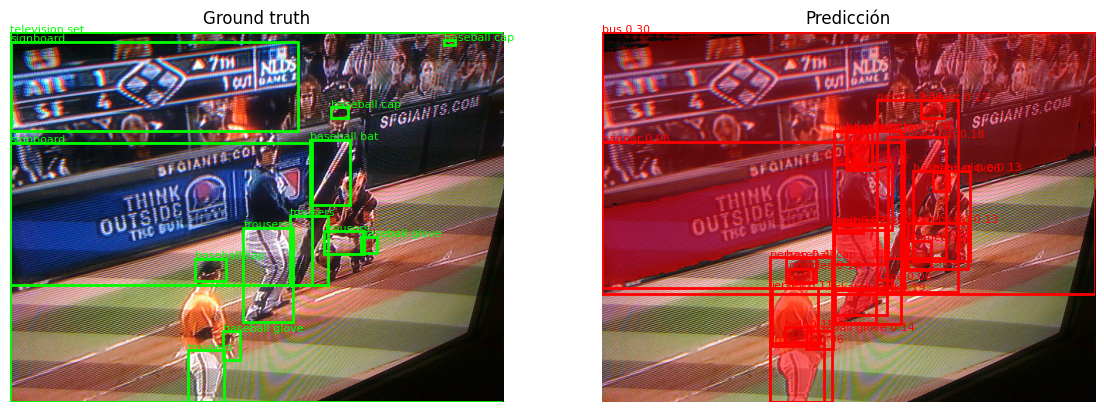

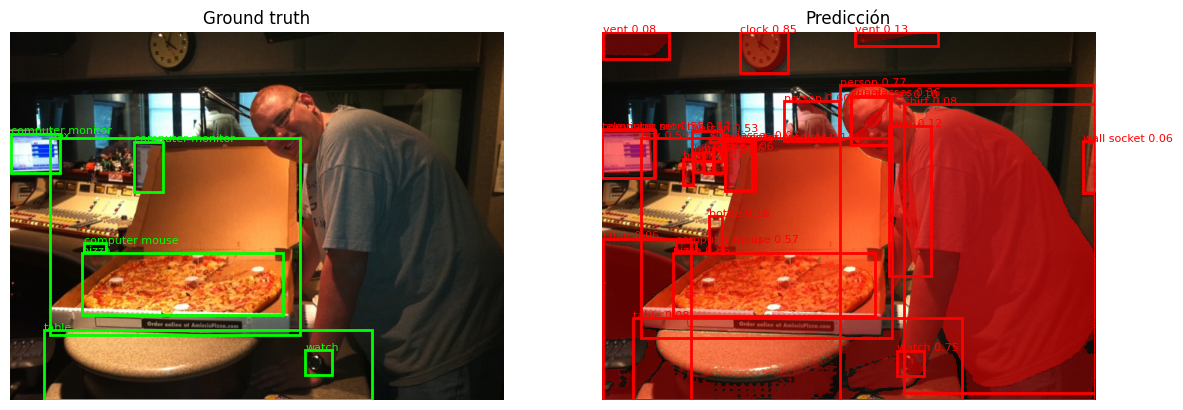

In [42]:
def mostrar_comparacion(image_id):
    escena = escenas_dev[image_id]
    imagen = np.array(Image.open(f"dataset_tpi/images/{escena['image']['file_name']}").convert("RGB"))
    info = lvis_gt.imgs[ARCHIVO_A_ID[escena["image"]["file_name"]]]
    fig, ejes = plt.subplots(1, 2, figsize=(14, 7))
    for eje, titulo in zip(ejes, ["Ground truth", "Predicción"]):
        eje.imshow(imagen); eje.set_title(titulo); eje.axis("off")
    for ann in lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[info["id"]])):
        x, y, w, h = ann["bbox"]
        ejes[0].add_patch(plt.Rectangle((x, y), w, h, fill=False, color="lime", linewidth=2))
        ejes[0].text(x, y, lvis_gt.cats[ann["category_id"]]["name"], color="lime", fontsize=8)
    for obj in escena["objects"]:
        x1, y1, x2, y2 = obj["bbox"]
        ejes[1].imshow(np.ma.masked_where(~rle_a_mascara(obj["mask"]), np.ones(imagen.shape[:2])), alpha=0.35, cmap="autumn")
        ejes[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", linewidth=2))
        ejes[1].text(x1, y1, f'{obj["category"]} {obj["confidence"]:.2f}', color="red", fontsize=8)
    plt.show()

mostrar_comparacion(df_por_imagen.iloc[0].image_id)    # peor caso
mostrar_comparacion(df_por_imagen.iloc[-1].image_id)   # mejor caso

> **Análisis de los casos extremos:**
> - **Peor caso (`tpi_0004`, F1 0,29):** es una foto de una transmisión de béisbol en un televisor. La escena dentro de la pantalla confunde al detector: aparece una caja grande de `bus` (confianza 0,30) que cubre casi toda la imagen, y los objetos pequeños (gorras y guantes) se pierden o quedan mal localizados. Hay 10 objetos anotados sin detectar contra 3 aciertos.
> - **Falla de recall (`tpi_0093`):** 9 aciertos y 1 solo falso positivo, pero 23 objetos sin detectar. Lo que se predice es correcto; el problema es lo que falta.
> - **Mejor caso (`tpi_0109`, F1 1,00):** los 7 objetos anotados se detectan sin falsos positivos, pero 20 de las 27 predicciones (por ejemplo `vent` o `wall socket`) son de clases no verificadas y se ignoran. Muestra por qué la precisión se informa junto con la cobertura.
> - **Caja correcta pero máscara mala:** al pasar de cajas a máscaras se pierden 57 aciertos (1.093 → 1.036), es decir, en el 5,2 % de los objetos bien localizados SAM2 recorta con IoU menor a 0,5.
> - **Preguntas:** el motor y la interpretación del LLM no fallan (60/60 interpretaciones correctas y respuestas idénticas entre modos), así que las 11 de 40 respuestas distintas a las del oráculo provienen de la detección. El conteo es lo más frágil (5/10), porque cualquier objeto perdido o sobrante cambia el número.
>
> Las celdas siguientes cuantifican qué clases se confunden y por qué se pierde cada objeto no detectado.

## ¿Qué clases se confunden y por qué se pierden los objetos?
Repetimos el emparejamiento de la evaluación de cajas (misma regla que `evaluar_imagen`: por clase, de mayor a menor confianza, IoU ≥ 0,5) y clasificamos cada error **solo con las anotaciones, para medir**:

**Falsos positivos** (predicciones que cuentan como error):
- *duplicado:* hay un objeto anotado de su clase con IoU ≥ 0,5, pero ya lo había tomado otra predicción;
- *clase confundida:* coincide (IoU ≥ 0,5) con un objeto anotado de otra clase;
- *mal localizada:* hay un objeto de su clase cerca (IoU entre 0,1 y 0,5), pero la caja no alcanza;
- *sin objeto:* no se superpone con nada anotado (o su clase se verificó como ausente).

**Falsos negativos** (objetos anotados no encontrados):
- *mal localizado:* hay una predicción de su clase con IoU entre 0,1 y 0,5 (o con IoU ≥ 0,5 que ya se usó para otro objeto);
- *clase confundida:* hay una predicción de otra clase con IoU ≥ 0,5;
- *no detectado:* ninguna predicción lo cubre.

La matriz de confusión junta todas las predicciones que no son acierto (falsos positivos e ignoradas) y que coinciden con un objeto anotado de **otra** clase.

Control: 353 falsos positivos y 697 falsos negativos (la evaluación de cajas dio 353 y 697)

Causas de los falsos positivos:


,cantidad,porcentaje
causa,,
sin objeto,209,59.2
mal localizada,126,35.7
clase confundida,18,5.1


Causas de los falsos negativos según el tamaño del objeto anotado:


tamano,large,medium,small,total
causa,,,,
clase confundida,10,30,57,97
mal localizado,3,39,174,216
no detectado,1,35,348,384
total,14,104,579,697


Clases con más objetos no encontrados:


,falsos_negativos
clase,
book,40
wheel,26
curtain,22
shoe,21
strap,20
broccoli,15
bicycle,15
car,14
handle,14


Pares de clases más confundidos (predicción no acertada que cae sobre un objeto anotado de otra clase):


,,cantidad
clase_real,clase_predicha,
drinking glass,cup,11
flowerpot,vase,11
spectacles,sunglasses,11
hat,baseball cap,10
baseball cap,hat,9
computer monitor,television set,8
tablecloth,table,8
goggles,sunglasses,7
watch,bracelet,4


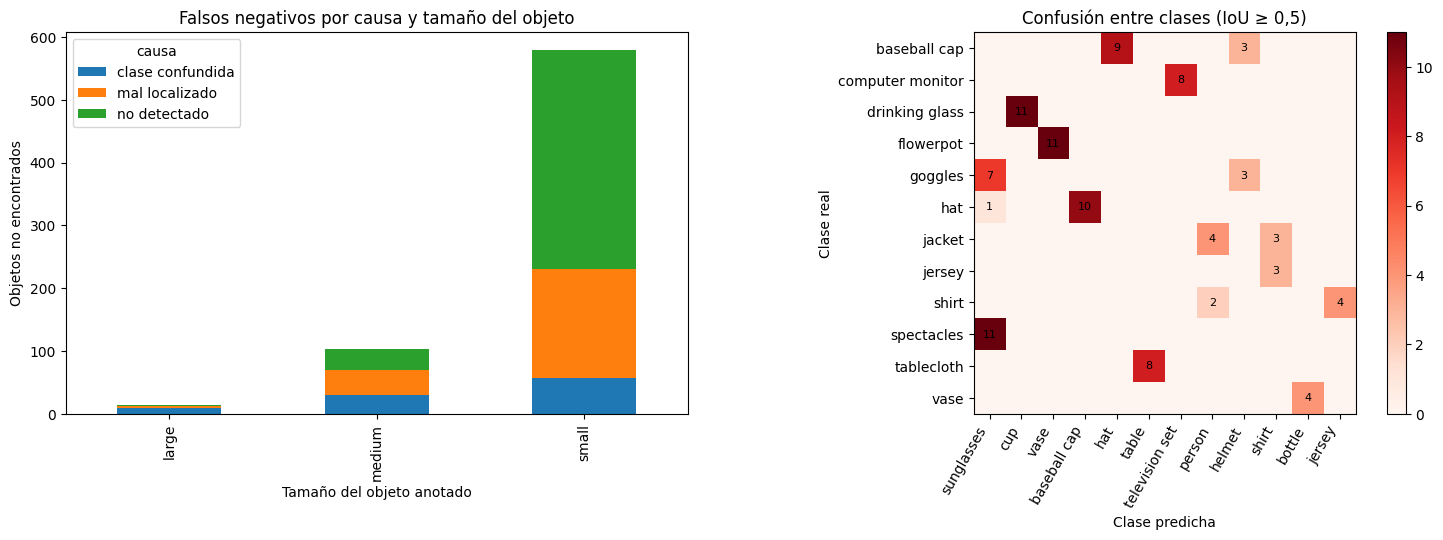

In [43]:
def emparejar_como_evaluacion(escena, iou_min=0.5):
    """Misma lógica que evaluar_imagen (cajas), pero devuelve el estado de cada predicción y los GT encontrados."""
    info = lvis_gt.imgs[ARCHIVO_A_ID[escena["image"]["file_name"]]]
    negativas, no_exhaustivas = set(info["neg_category_ids"]), set(info["not_exhaustive_category_ids"])
    anns = lvis_gt.load_anns(lvis_gt.get_ann_ids(img_ids=[info["id"]]))
    gt_por_cat = defaultdict(list)
    for ann in anns:
        gt_por_cat[ann["category_id"]].append(ann)
    estados, encontrados = [], set()
    for cat in set(gt_por_cat) | {o["category_id"] for o in escena["objects"]}:
        gts, usados = gt_por_cat.get(cat, []), set()
        for pred in sorted([o for o in escena["objects"] if o["category_id"] == cat], key=lambda o: -o["confidence"]):
            mejor, mejor_iou = None, iou_min
            for j, gt in enumerate(gts):
                if j in usados:
                    continue
                iou = iou_cajas(xyxy_a_xywh(pred["bbox"]), gt["bbox"])
                if iou >= mejor_iou:
                    mejor, mejor_iou = j, iou
            if mejor is not None:
                usados.add(mejor)
                encontrados.add(gts[mejor]["id"])
                estados.append((pred, "tp"))
            elif cat in negativas or (gts and cat not in no_exhaustivas):
                estados.append((pred, "fp"))
            else:
                estados.append((pred, "ignorada"))
    return info, anns, estados, encontrados

def nombre_cat(cat_id):
    return lvis_gt.cats[cat_id]["name"]

def tamano_gt(ann, info):
    return tamano_relativo(ann["area"] / (info["width"] * info["height"]))

causas_fp, causas_fn, confusiones = [], [], []
for escena in escenas_dev.values():
    info, anns, estados, encontrados = emparejar_como_evaluacion(escena)
    preds = [p for p, _ in estados]
    for pred, estado in estados:
        if estado == "tp":
            continue
        caja = xyxy_a_xywh(pred["bbox"])
        ious = [(iou_cajas(caja, a["bbox"]), a) for a in anns]
        misma = [i for i, a in ious if a["category_id"] == pred["category_id"]]
        otra = [(i, a) for i, a in ious if a["category_id"] != pred["category_id"] and i >= 0.5]
        if otra:
            _, gt_otra = max(otra, key=lambda x: x[0])
            confusiones.append({"clase_real": nombre_cat(gt_otra["category_id"]), "clase_predicha": nombre_cat(pred["category_id"]),
                                "estado": estado})
        if estado != "fp":
            continue
        if any(i >= 0.5 for i in misma):
            causa = "duplicado"
        elif otra:
            causa = "clase confundida"
        elif any(i >= 0.1 for i in misma):
            causa = "mal localizada"
        else:
            causa = "sin objeto"
        causas_fp.append({"causa": causa, "clase": nombre_cat(pred["category_id"])})
    for ann in anns:
        if ann["id"] in encontrados:
            continue
        ious = [(iou_cajas(xyxy_a_xywh(p["bbox"]), ann["bbox"]), p) for p in preds]
        if any(i >= 0.1 for i, p in ious if p["category_id"] == ann["category_id"]):
            causa = "mal localizado"
        elif any(i >= 0.5 for i, p in ious if p["category_id"] != ann["category_id"]):
            causa = "clase confundida"
        else:
            causa = "no detectado"
        causas_fn.append({"causa": causa, "clase": nombre_cat(ann["category_id"]), "tamano": tamano_gt(ann, info)})

df_fp, df_fn, df_conf = pd.DataFrame(causas_fp), pd.DataFrame(causas_fn), pd.DataFrame(confusiones)
print(f"Control: {len(df_fp)} falsos positivos y {len(df_fn)} falsos negativos "
      f"(la evaluación de cajas dio {metricas['cajas']['fp']} y {metricas['cajas']['fn']})")

print("\nCausas de los falsos positivos:")
display(df_fp.causa.value_counts().to_frame("cantidad").assign(porcentaje=lambda d: (d.cantidad / d.cantidad.sum() * 100).round(1)))
print("Causas de los falsos negativos según el tamaño del objeto anotado:")
tabla_fn = pd.crosstab(df_fn.causa, df_fn.tamano, margins=True, margins_name="total")
display(tabla_fn)
print("Clases con más objetos no encontrados:")
display(df_fn.clase.value_counts().head(10).to_frame("falsos_negativos"))

print("Pares de clases más confundidos (predicción no acertada que cae sobre un objeto anotado de otra clase):")
top_pares = df_conf.groupby(["clase_real", "clase_predicha"]).size().sort_values(ascending=False).head(15)
display(top_pares.to_frame("cantidad"))

df_fp.to_csv("errores_falsos_positivos.csv", index=False)
df_fn.to_csv("errores_falsos_negativos.csv", index=False)
df_conf.to_csv("errores_confusion_clases.csv", index=False)

# Matriz de confusión entre las clases reales que más se confunden
clases_top = df_conf.clase_real.value_counts().head(12).index
sub = df_conf[df_conf.clase_real.isin(clases_top)]
matriz = pd.crosstab(sub.clase_real, sub.clase_predicha)
matriz = matriz[matriz.sum().sort_values(ascending=False).index[:12]]
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
tabla_fn.drop(index="total", columns="total").T.plot(kind="bar", stacked=True, ax=ejes[0])
ejes[0].set_title("Falsos negativos por causa y tamaño del objeto")
ejes[0].set_xlabel("Tamaño del objeto anotado")
ejes[0].set_ylabel("Objetos no encontrados")
im = ejes[1].imshow(matriz.values, cmap="Reds")
ejes[1].set_xticks(range(matriz.shape[1]), matriz.columns, rotation=60, ha="right")
ejes[1].set_yticks(range(matriz.shape[0]), matriz.index)
for f in range(matriz.shape[0]):
    for c in range(matriz.shape[1]):
        if matriz.values[f, c]:
            ejes[1].text(c, f, matriz.values[f, c], ha="center", va="center", fontsize=8)
ejes[1].set_xlabel("Clase predicha")
ejes[1].set_ylabel("Clase real")
ejes[1].set_title("Confusión entre clases (IoU ≥ 0,5)")
fig.colorbar(im, ax=ejes[1])
plt.tight_layout()
plt.show()

> **Lectura de los errores:**
> - **Falsos negativos (697):** el 55,1 % no tiene ninguna predicción cerca (*no detectado*), el 31,0 % está mal localizado y el 13,9 % recibió otra clase. El 83,1 % (579) son objetos *small*, así que el cuello de botella es el recall de objetos pequeños.
> - **Falsos positivos (353):** el 59,2 % no tiene ningún objeto anotado debajo, el 35,7 % está mal localizado y el 5,1 % es una confusión de clase. No queda ningún duplicado, lo que confirma que el NMS, WBF y el filtro de contención cumplen su función.
> - **Confusiones de clase:** se dan entre clases vecinas: `drinking glass` → `cup` (11), `flowerpot` → `vase` (11), `spectacles` → `sunglasses` (11), `hat` ↔ `baseball cap` (10 y 9), `computer monitor` → `television set` (8) y `tablecloth` → `table` (8). El detector las separa solo por el texto del prompt.

# 13. Resumen: F1 final
F1 de detección (cajas) y de segmentación (máscaras) sobre las 120 imágenes de desarrollo, con IoU de al menos 0,5 y las reglas de LVIS. El enunciado pide un F1 de detección de al menos 0,40 para aprobar y de 0,50 para promocionar.

F1 de detección (cajas):       0.675
F1 de segmentación (máscaras): 0.642
Precisión: 0.756 | Recall: 0.611 | Cobertura de evaluación: 0.393
Nivel según F1 de detección: Promoción (F1 ≥ 0,50)


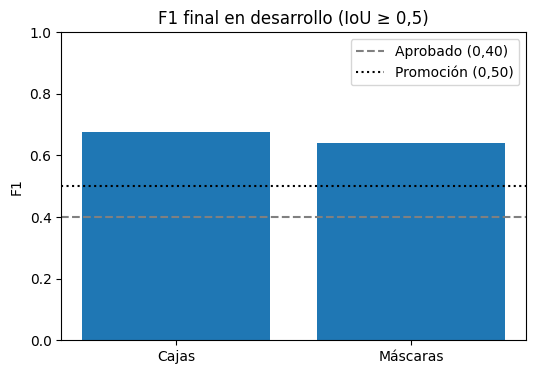

In [44]:
f1_cajas = metricas["cajas"]["f1"]
f1_mascaras = metricas["mascaras"]["f1"]

print(f"F1 de detección (cajas):       {f1_cajas:.3f}")
print(f"F1 de segmentación (máscaras): {f1_mascaras:.3f}")
print(f"Precisión: {metricas['cajas']['precision']:.3f} | Recall: {metricas['cajas']['recall']:.3f} | "
      f"Cobertura de evaluación: {metricas['cajas']['cobertura']:.3f}")

if f1_cajas >= 0.50:
    nivel = "Promoción (F1 ≥ 0,50)"
elif f1_cajas >= 0.40:
    nivel = "Aprobado (F1 ≥ 0,40)"
else:
    nivel = "Por debajo del mínimo para aprobar (0,40)"
print("Nivel según F1 de detección:", nivel)

plt.figure(figsize=(6, 4))
plt.bar(["Cajas", "Máscaras"], [f1_cajas, f1_mascaras])
plt.axhline(0.40, color="gray", linestyle="--", label="Aprobado (0,40)")
plt.axhline(0.50, color="black", linestyle=":", label="Promoción (0,50)")
plt.ylim(0, 1)
plt.ylabel("F1")
plt.title("F1 final en desarrollo (IoU ≥ 0,5)")
plt.legend()
plt.show()